In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/dim_cost_center_group.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/acdoca_universal_journal.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/dim_cost_center.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/dim_gl_account.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/plan_versions.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/aggregate_revenue_results.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/dim_profit_center.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/acdoca_actuals.csv
/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/dim_company_code.csv


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

input/
  datasets/
    shrutimeshram29/
      financial-fpa-analytics-dataset/
        dim_cost_center_group.csv
        acdoca_universal_journal.csv
        dim_cost_center.csv
        dim_gl_account.csv
        plan_versions.csv
        aggregate_revenue_results.csv
        dim_profit_center.csv
        acdoca_actuals.csv
        dim_company_code.csv


In [3]:
import pandas as pd
from pathlib import Path

# Location of our dataset
DATA_PATH = Path(
    "/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset"
)

# Find all CSV files
files = list(DATA_PATH.glob("*.csv"))

# Number of files
print("Number of CSV files:", len(files))

# File names
print("\nFiles:")

for file in files:
    print("-", file.name)

Number of CSV files: 9

Files:
- dim_cost_center_group.csv
- acdoca_universal_journal.csv
- dim_cost_center.csv
- dim_gl_account.csv
- plan_versions.csv
- aggregate_revenue_results.csv
- dim_profit_center.csv
- acdoca_actuals.csv
- dim_company_code.csv


In [4]:
import os

print("FILE SIZES")
print("=" * 60)

for file in files:
    size_mb = os.path.getsize(file) / (1024 * 1024)
    print(f"{file.name:40} {size_mb:8.2f} MB")

FILE SIZES
dim_cost_center_group.csv                    0.00 MB
acdoca_universal_journal.csv                18.16 MB
dim_cost_center.csv                          0.00 MB
dim_gl_account.csv                           0.00 MB
plan_versions.csv                            1.56 MB
aggregate_revenue_results.csv                0.00 MB
dim_profit_center.csv                        0.00 MB
acdoca_actuals.csv                          16.52 MB
dim_company_code.csv                         0.00 MB


In [5]:
import os

print("FILE SIZES")
print("=" * 60)

for file in files:
    size_mb = os.path.getsize(file) / (1024 * 1024)
    print(f"{file.name:40} {size_mb:8.2f} MB")

FILE SIZES
dim_cost_center_group.csv                    0.00 MB
acdoca_universal_journal.csv                18.16 MB
dim_cost_center.csv                          0.00 MB
dim_gl_account.csv                           0.00 MB
plan_versions.csv                            1.56 MB
aggregate_revenue_results.csv                0.00 MB
dim_profit_center.csv                        0.00 MB
acdoca_actuals.csv                          16.52 MB
dim_company_code.csv                         0.00 MB


In [6]:
gl_account = pd.read_csv(
    DATA_PATH / "dim_gl_account.csv"
)

In [7]:
gl_account.head()

,HKONT,TXT50,CATEGORY,NORMAL_SIDE,SEASONALITY,PL_RATIO
0,400000,Revenue - Product,REVENUE,H,revenue,0.700
1,410000,Revenue - Services,REVENUE,H,revenue,0.300
2,500000,COGS - Material,COGS,S,cogs,0.420
3,510000,COGS - Subcontracting,COGS,S,cogs,0.130
4,600000,Personnel - Salaries,PERSONNEL,S,flat,0.175


In [8]:
gl_account.shape

(19, 6)

In [9]:
gl_account.columns

Index(['HKONT', 'TXT50', 'CATEGORY', 'NORMAL_SIDE', 'SEASONALITY', 'PL_RATIO'], dtype='object')

In [10]:
gl_account.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HKONT        19 non-null     int64  
 1   TXT50        19 non-null     object 
 2   CATEGORY     19 non-null     object 
 3   NORMAL_SIDE  19 non-null     object 
 4   SEASONALITY  19 non-null     object 
 5   PL_RATIO     19 non-null     float64
dtypes: float64(1), int64(1), object(4)
memory usage: 1.0+ KB


In [11]:
gl_account.isna().sum()

HKONT          0
TXT50          0
CATEGORY       0
NORMAL_SIDE    0
SEASONALITY    0
PL_RATIO       0
dtype: int64

In [12]:
gl_account.duplicated().sum()

np.int64(0)

In [13]:
actuals_path = DATA_PATH / "acdoca_actuals.csv"

actuals = pd.read_csv(
    actuals_path,
    low_memory=False
)

print("Number of rows:", f"{actuals.shape[0]:,}")
print("Number of columns:", actuals.shape[1])

print("\nColumn names:")
print(actuals.columns.tolist())

print("\nFirst 5 rows:")
display(actuals.head())

Number of rows: 159,934
Number of columns: 19

Column names:
['BUKRS', 'BELNR', 'GJAHR', 'MONAT', 'BUDAT', 'BLDAT', 'BLART', 'WAERS', 'VERSION', 'USNAM', 'STBLG', 'BUZEI', 'BSCHL', 'SHKZG', 'HKONT', 'KOSTL', 'PRCTR', 'DMBTR', 'WRBTR']

First 5 rows:


,BUKRS,BELNR,GJAHR,MONAT,BUDAT,BLDAT,BLART,WAERS,VERSION,USNAM,STBLG,BUZEI,BSCHL,SHKZG,HKONT,KOSTL,PRCTR,DMBTR,WRBTR
0,1000,100001,2022,1,2022-01-26,2022-01-15,DR,EUR,0,USER025,NaN,1,50,H,400000,10000001.0,P100001,1804899.87,1804899.87
1,1000,100001,2022,1,2022-01-26,2022-01-15,DR,EUR,0,USER025,NaN,2,40,S,140000,NaN,P100001,1804899.87,1804899.87
2,1000,100002,2022,1,2022-01-05,2021-12-25,DR,EUR,0,USER012,NaN,1,50,H,400000,10000001.0,P100001,755188.00,755188.00
3,1000,100002,2022,1,2022-01-05,2021-12-25,DR,EUR,0,USER012,NaN,2,40,S,140000,NaN,P100001,755188.00,755188.00
4,1000,100003,2022,1,2022-01-12,2022-01-11,DR,EUR,0,USER015,NaN,1,50,H,400000,10000001.0,P100001,1772710.39,1772710.39


In [14]:
column_mapping = {
    "BUKRS": "company_code",
    "BELNR": "document_number",
    "GJAHR": "fiscal_year",
    "MONAT": "fiscal_month",
    "BUDAT": "posting_date",
    "BLDAT": "document_date",
    "BLART": "document_type",
    "WAERS": "currency",
    "VERSION": "accounting_version",
    "USNAM": "created_by",
    "STBLG": "reversal_document",
    "BUZEI": "line_item",
    "BSCHL": "posting_key",
    "SHKZG": "debit_credit",
    "HKONT": "gl_account",
    "KOSTL": "cost_center",
    "PRCTR": "profit_center",
    "DMBTR": "local_currency_amount",
    "WRBTR": "document_currency_amount"
}

In [15]:
actuals_clean = actuals.rename(columns=column_mapping)

In [16]:
print(actuals_clean.columns.tolist())

['company_code', 'document_number', 'fiscal_year', 'fiscal_month', 'posting_date', 'document_date', 'document_type', 'currency', 'accounting_version', 'created_by', 'reversal_document', 'line_item', 'posting_key', 'debit_credit', 'gl_account', 'cost_center', 'profit_center', 'local_currency_amount', 'document_currency_amount']


In [17]:
print("Original columns:")
print(actuals.columns.tolist())

print("\nCleaned columns:")
print(actuals_clean.columns.tolist())

Original columns:
['BUKRS', 'BELNR', 'GJAHR', 'MONAT', 'BUDAT', 'BLDAT', 'BLART', 'WAERS', 'VERSION', 'USNAM', 'STBLG', 'BUZEI', 'BSCHL', 'SHKZG', 'HKONT', 'KOSTL', 'PRCTR', 'DMBTR', 'WRBTR']

Cleaned columns:
['company_code', 'document_number', 'fiscal_year', 'fiscal_month', 'posting_date', 'document_date', 'document_type', 'currency', 'accounting_version', 'created_by', 'reversal_document', 'line_item', 'posting_key', 'debit_credit', 'gl_account', 'cost_center', 'profit_center', 'local_currency_amount', 'document_currency_amount']


In [18]:
display(actuals_clean.head())

,company_code,document_number,fiscal_year,fiscal_month,posting_date,document_date,document_type,currency,accounting_version,created_by,reversal_document,line_item,posting_key,debit_credit,gl_account,cost_center,profit_center,local_currency_amount,document_currency_amount
0,1000,100001,2022,1,2022-01-26,2022-01-15,DR,EUR,0,USER025,NaN,1,50,H,400000,10000001.0,P100001,1804899.87,1804899.87
1,1000,100001,2022,1,2022-01-26,2022-01-15,DR,EUR,0,USER025,NaN,2,40,S,140000,NaN,P100001,1804899.87,1804899.87
2,1000,100002,2022,1,2022-01-05,2021-12-25,DR,EUR,0,USER012,NaN,1,50,H,400000,10000001.0,P100001,755188.00,755188.00
3,1000,100002,2022,1,2022-01-05,2021-12-25,DR,EUR,0,USER012,NaN,2,40,S,140000,NaN,P100001,755188.00,755188.00
4,1000,100003,2022,1,2022-01-12,2022-01-11,DR,EUR,0,USER015,NaN,1,50,H,400000,10000001.0,P100001,1772710.39,1772710.39


In [19]:
actuals_clean.dtypes

company_code                  int64
document_number               int64
fiscal_year                   int64
fiscal_month                  int64
posting_date                 object
document_date                object
document_type                object
currency                     object
accounting_version            int64
created_by                   object
reversal_document           float64
line_item                     int64
posting_key                   int64
debit_credit                 object
gl_account                    int64
cost_center                 float64
profit_center                object
local_currency_amount       float64
document_currency_amount    float64
dtype: object

In [20]:
actuals_clean["posting_date"] = pd.to_datetime(
    actuals_clean["posting_date"],
    errors="coerce"
)

actuals_clean["document_date"] = pd.to_datetime(
    actuals_clean["document_date"],
    errors="coerce"
)

In [21]:
print(actuals_clean[["posting_date", "document_date"]].dtypes)

posting_date     datetime64[ns]
document_date    datetime64[ns]
dtype: object


In [22]:
missing_values = (
    actuals_clean.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_values.to_frame("missing_count"))

,missing_count
reversal_document,158590
cost_center,79967
company_code,0
fiscal_year,0
document_number,0
document_date,0
fiscal_month,0
document_type,0
currency,0
accounting_version,0


In [23]:
missing_summary = pd.DataFrame({
    "missing_count": actuals_clean.isna().sum(),
    "missing_percentage": (
        actuals_clean.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
reversal_document,158590,99.16
cost_center,79967,50.00
company_code,0,0.00
fiscal_year,0,0.00
document_number,0,0.00
document_date,0,0.00
fiscal_month,0,0.00
document_type,0,0.00
currency,0,0.00
accounting_version,0,0.00


In [24]:
duplicate_count = actuals_clean.duplicated().sum()

print("Duplicate rows:", f"{duplicate_count:,}")

Duplicate rows: 0


In [25]:
print("Company codes:")
print(actuals_clean["company_code"].unique())

Company codes:
[1000 2000 3000]


In [26]:
print("Fiscal years:")
print(sorted(actuals_clean["fiscal_year"].unique()))

Fiscal years:
[np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [27]:
print("Fiscal months:")
print(sorted(actuals_clean["fiscal_month"].unique()))

Fiscal months:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]


In [28]:
print("Currencies:")
print(actuals_clean["currency"].value_counts())

Currencies:
currency
EUR    62394
USD    53194
INR    44346
Name: count, dtype: int64


In [29]:
print("Debit/Credit distribution:")
print(actuals_clean["debit_credit"].value_counts())

Debit/Credit distribution:
debit_credit
H    79967
S    79967
Name: count, dtype: int64


In [30]:
print("Number of unique G/L accounts:")
print(actuals_clean["gl_account"].nunique())

Number of unique G/L accounts:
19


In [31]:
print(
    actuals_clean["gl_account"].value_counts().head(20)
)

gl_account
160000    36367
170000    26721
600000    12051
620000    11990
740000     9072
199000     8781
780000     8781
140000     6737
700000     6153
720000     5971
710000     3558
730000     3452
510000     3412
410000     3404
500000     3340
400000     3333
610000     2777
750000     2673
490000     1361
Name: count, dtype: int64


In [32]:
actuals_clean["local_currency_amount"].describe()

count    1.599340e+05
mean     3.266729e+05
std      1.153534e+06
min      1.040000e+00
25%      1.015526e+04
50%      3.952067e+04
75%      1.439382e+05
max      3.855587e+07
Name: local_currency_amount, dtype: float64

In [33]:
missing_summary[
    missing_summary["missing_count"] > 0
]

,missing_count,missing_percentage
reversal_document,158590,99.16
cost_center,79967,50.00


In [34]:
duplicate_count = actuals_clean.duplicated().sum()

print("Duplicate rows:", f"{duplicate_count:,}")

Duplicate rows: 0


In [35]:
line_item_duplicates = actuals_clean.duplicated(
    subset=["document_number", "line_item"]
).sum()

print(
    "Duplicate document + line item combinations:",
    f"{line_item_duplicates:,}"
)

Duplicate document + line item combinations: 144,118


In [36]:
print("Earliest posting date:")
print(actuals_clean["posting_date"].min())

print("\nLatest posting date:")
print(actuals_clean["posting_date"].max())

Earliest posting date:
2022-01-01 00:00:00

Latest posting date:
2025-12-31 00:00:00


In [37]:
currency_distribution = (
    actuals_clean["currency"]
    .value_counts()
)

display(currency_distribution)

currency
EUR    62394
USD    53194
INR    44346
Name: count, dtype: int64

In [38]:
debit_credit_distribution = (
    actuals_clean["debit_credit"]
    .value_counts()
)

display(debit_credit_distribution)

debit_credit
H    79967
S    79967
Name: count, dtype: int64

In [39]:
actuals_clean["local_currency_amount"].describe()

count    1.599340e+05
mean     3.266729e+05
std      1.153534e+06
min      1.040000e+00
25%      1.015526e+04
50%      3.952067e+04
75%      1.439382e+05
max      3.855587e+07
Name: local_currency_amount, dtype: float64

In [40]:
duplicate_key_count = actuals_clean.duplicated(
    subset=[
        "company_code",
        "fiscal_year",
        "document_number",
        "line_item"
    ]
).sum()

print(
    "Duplicate company + year + document + line item:",
    f"{duplicate_key_count:,}"
)

Duplicate company + year + document + line item: 0


In [41]:
gl_account = pd.read_csv(
    DATA_PATH / "dim_gl_account.csv"
)

gl_account = gl_account.rename(
    columns={
        "HKONT": "gl_account",
        "TXT50": "gl_account_name",
        "CATEGORY": "financial_category"
    }
)

display(gl_account.head())

,gl_account,gl_account_name,financial_category,NORMAL_SIDE,SEASONALITY,PL_RATIO
0,400000,Revenue - Product,REVENUE,H,revenue,0.700
1,410000,Revenue - Services,REVENUE,H,revenue,0.300
2,500000,COGS - Material,COGS,S,cogs,0.420
3,510000,COGS - Subcontracting,COGS,S,cogs,0.130
4,600000,Personnel - Salaries,PERSONNEL,S,flat,0.175


In [42]:
actuals_analysis = actuals_clean.merge(
    gl_account[
        ["gl_account", "gl_account_name", "financial_category"]
    ],
    on="gl_account",
    how="left"
)

display(
    actuals_analysis[
        [
            "gl_account",
            "gl_account_name",
            "financial_category",
            "cost_center"
        ]
    ].head()
)

,gl_account,gl_account_name,financial_category,cost_center
0,400000,Revenue - Product,REVENUE,10000001.0
1,140000,Accounts Receivable,BALANCE_SHEET,NaN
2,400000,Revenue - Product,REVENUE,10000001.0
3,140000,Accounts Receivable,BALANCE_SHEET,NaN
4,400000,Revenue - Product,REVENUE,10000001.0


In [43]:
cost_center_analysis = (
    actuals_analysis
    .groupby("financial_category")
    .agg(
        total_transactions=("gl_account", "size"),
        missing_cost_centers=(
            "cost_center",
            lambda x: x.isna().sum()
        )
    )
)

cost_center_analysis["missing_percentage"] = (
    cost_center_analysis["missing_cost_centers"]
    / cost_center_analysis["total_transactions"]
    * 100
).round(2)

display(cost_center_analysis)

,total_transactions,missing_cost_centers,missing_percentage
financial_category,,,
BALANCE_SHEET,79967,79967,100.0
COGS,6752,0,0.0
DEPRECIATION,8781,0,0.0
OPEX,30879,0,0.0
PERSONNEL,26818,0,0.0
REVENUE,6737,0,0.0


In [44]:
category_summary = (
    actuals_analysis
    .groupby("financial_category")
    .agg(
        transaction_count=("gl_account", "size"),
        total_amount=("local_currency_amount", "sum"),
        average_amount=("local_currency_amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

display(category_summary)

,transaction_count,total_amount,average_amount
financial_category,,,
BALANCE_SHEET,79967,2.612305e+10,3.266729e+05
REVENUE,6737,1.335640e+10,1.982545e+06
COGS,6752,7.536470e+09,1.116183e+06
PERSONNEL,26818,3.144246e+09,1.172439e+05
OPEX,30879,1.543805e+09,4.999532e+04
DEPRECIATION,8781,5.421288e+08,6.173884e+04


In [45]:
company_currency_summary = (
    actuals_analysis
    .groupby(["company_code", "currency"])
    .agg(
        transaction_count=("gl_account", "size"),
        total_local_amount=("local_currency_amount", "sum"),
        total_document_amount=("document_currency_amount", "sum")
    )
    .reset_index()
)

display(company_currency_summary)

,company_code,currency,transaction_count,total_local_amount,total_document_amount
0,1000,EUR,62394,2.330637e+10,2.330637e+10
1,2000,USD,53194,1.318867e+10,1.318867e+10
2,3000,INR,44346,1.575106e+10,1.575106e+10


In [46]:
debit_credit_amount = (
    actuals_analysis
    .groupby("debit_credit")
    .agg(
        transaction_count=("gl_account", "size"),
        total_amount=("local_currency_amount", "sum"),
        average_amount=("local_currency_amount", "mean"),
        minimum_amount=("local_currency_amount", "min"),
        maximum_amount=("local_currency_amount", "max")
    )
    .reset_index()
)

display(debit_credit_amount)

,debit_credit,transaction_count,total_amount,average_amount,minimum_amount,maximum_amount
0,H,79967,2.612305e+10,326672.927745,1.04,38555866.89
1,S,79967,2.612305e+10,326672.927745,1.04,38555866.89


In [47]:
category_debit_credit = (
    actuals_analysis
    .groupby(["financial_category", "debit_credit"])
    .agg(
        transaction_count=("gl_account", "size"),
        total_amount=("local_currency_amount", "sum")
    )
    .reset_index()
)

display(category_debit_credit)

,financial_category,debit_credit,transaction_count,total_amount
0,BALANCE_SHEET,H,72558,1.259874e+10
1,BALANCE_SHEET,S,7409,1.352431e+10
2,COGS,H,125,1.415041e+08
3,COGS,S,6627,7.394965e+09
4,DEPRECIATION,S,8781,5.421288e+08
5,OPEX,H,500,2.450919e+07
6,OPEX,S,30379,1.519296e+09
7,PERSONNEL,H,47,1.892353e+06
8,PERSONNEL,S,26771,3.142354e+09
9,REVENUE,H,6737,1.335640e+10


In [48]:
document_balance = (
    actuals_analysis
    .groupby(
        ["company_code", "fiscal_year", "document_number", "debit_credit"]
    )["local_currency_amount"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

display(document_balance.head(20))

debit_credit,company_code,fiscal_year,document_number,H,S
0,1000,2022,100001,1804899.87,1804899.87
1,1000,2022,100002,755188.00,755188.00
2,1000,2022,100003,1772710.39,1772710.39
3,1000,2022,100004,1155058.98,1155058.98
4,1000,2022,100005,7719954.87,7719954.87
5,1000,2022,100006,271724.79,271724.79
6,1000,2022,100007,1303384.50,1303384.50
7,1000,2022,100008,2698903.26,2698903.26
8,1000,2022,100009,267547.01,267547.01
9,1000,2022,100010,2377257.52,2377257.52


In [49]:
document_balance["balance_difference"] = (
    document_balance["H"] -
    document_balance["S"]
)

print(
    "Total documents:",
    f"{len(document_balance):,}"
)

print(
    "Balanced documents:",
    (document_balance["balance_difference"].abs() < 0.01).sum()
)

print(
    "Unbalanced documents:",
    (document_balance["balance_difference"].abs() >= 0.01).sum()
)

Total documents: 79,967
Balanced documents: 79967
Unbalanced documents: 0


In [50]:
print(actuals_analysis["debit_credit"].unique())

['H' 'S']


In [51]:
print(actuals_analysis["debit_credit"].value_counts())

debit_credit
H    79967
S    79967
Name: count, dtype: int64


In [52]:
actuals_analysis["signed_amount"] = (
    actuals_analysis["local_currency_amount"]
    .where(
        actuals_analysis["debit_credit"] == "S",
        -actuals_analysis["local_currency_amount"]
    )
)

display(
    actuals_analysis[
        [
            "gl_account",
            "financial_category",
            "debit_credit",
            "local_currency_amount",
            "signed_amount"
        ]
    ].head(10)
)

,gl_account,financial_category,debit_credit,local_currency_amount,signed_amount
0,400000,REVENUE,H,1804899.87,-1804899.87
1,140000,BALANCE_SHEET,S,1804899.87,1804899.87
2,400000,REVENUE,H,755188.00,-755188.00
3,140000,BALANCE_SHEET,S,755188.00,755188.00
4,400000,REVENUE,H,1772710.39,-1772710.39
5,140000,BALANCE_SHEET,S,1772710.39,1772710.39
6,400000,REVENUE,H,1155058.98,-1155058.98
7,140000,BALANCE_SHEET,S,1155058.98,1155058.98
8,400000,REVENUE,H,7719954.87,-7719954.87
9,140000,BALANCE_SHEET,S,7719954.87,7719954.87


In [53]:
actuals_analysis[
    ["debit_credit", "local_currency_amount", "signed_amount"]
].groupby("debit_credit").agg(
    original_total=("local_currency_amount", "sum"),
    signed_total=("signed_amount", "sum")
)

,original_total,signed_total
debit_credit,,
H,2.612305e+10,-2.612305e+10
S,2.612305e+10,2.612305e+10


In [54]:
category_summary = (
    actuals_analysis
    .groupby("financial_category")["signed_amount"]
    .agg(
        transaction_count="count",
        total_signed_amount="sum",
        average_signed_amount="mean"
    )
    .reset_index()
    .sort_values("total_signed_amount", ascending=False)
)

display(category_summary)

,financial_category,transaction_count,total_signed_amount,average_signed_amount
1,COGS,6752,7.253461e+09,1.074269e+06
4,PERSONNEL,26818,3.140462e+09,1.171028e+05
3,OPEX,30879,1.494787e+09,4.840788e+04
0,BALANCE_SHEET,79967,9.255652e+08,1.157434e+04
2,DEPRECIATION,8781,5.421288e+08,6.173884e+04
5,REVENUE,6737,-1.335640e+10,-1.982545e+06


In [55]:
pnl_categories = [
    "REVENUE",
    "COGS",
    "PERSONNEL",
    "OPEX",
    "DEPRECIATION"
]

pnl_data = actuals_analysis[
    actuals_analysis["financial_category"].isin(pnl_categories)
].copy()

print("P&L transactions:", f"{len(pnl_data):,}")

display(
    pnl_data[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "financial_category",
            "debit_credit",
            "local_currency_amount",
            "signed_amount",
            "currency"
        ]
    ].head(10)
)

P&L transactions: 79,967


,company_code,fiscal_year,fiscal_month,financial_category,debit_credit,local_currency_amount,signed_amount,currency
0,1000,2022,1,REVENUE,H,1804899.87,-1804899.87,EUR
2,1000,2022,1,REVENUE,H,755188.00,-755188.00,EUR
4,1000,2022,1,REVENUE,H,1772710.39,-1772710.39,EUR
6,1000,2022,1,REVENUE,H,1155058.98,-1155058.98,EUR
8,1000,2022,1,REVENUE,H,7719954.87,-7719954.87,EUR
10,1000,2022,1,REVENUE,H,271724.79,-271724.79,EUR
12,1000,2022,1,REVENUE,H,1303384.50,-1303384.50,EUR
14,1000,2022,1,REVENUE,H,2698903.26,-2698903.26,EUR
16,1000,2022,1,REVENUE,H,267547.01,-267547.01,EUR
18,1000,2022,1,REVENUE,H,2377257.52,-2377257.52,EUR


In [56]:
monthly_category = (
    pnl_data
    .groupby(
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "financial_category"
        ]
    )["signed_amount"]
    .sum()
    .reset_index()
)

display(monthly_category.head(20))


,company_code,fiscal_year,fiscal_month,currency,financial_category,signed_amount
0,1000,2022,1,EUR,COGS,4.908376e+07
1,1000,2022,1,EUR,DEPRECIATION,4.129441e+06
2,1000,2022,1,EUR,OPEX,1.037997e+07
3,1000,2022,1,EUR,PERSONNEL,2.030701e+07
4,1000,2022,1,EUR,REVENUE,-1.066742e+08
5,1000,2022,2,EUR,COGS,4.819201e+07
6,1000,2022,2,EUR,DEPRECIATION,4.384970e+06
7,1000,2022,2,EUR,OPEX,1.129209e+07
8,1000,2022,2,EUR,PERSONNEL,1.968774e+07
9,1000,2022,2,EUR,REVENUE,-1.150038e+08


In [57]:
monthly_pnl = (
    monthly_category
    .pivot_table(
        index=[
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency"
        ],
        columns="financial_category",
        values="signed_amount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

monthly_pnl.columns.name = None

display(monthly_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,COGS,DEPRECIATION,OPEX,PERSONNEL,REVENUE
0,1000,2022,1,EUR,49083757.34,4129440.87,10379974.91,20307008.37,-1.066742e+08
1,1000,2022,2,EUR,48192012.88,4384969.94,11292085.33,19687736.89,-1.150038e+08
2,1000,2022,3,EUR,60310274.70,4474096.88,10633436.67,25767533.68,-1.385871e+08
3,1000,2022,4,EUR,50598265.04,4310775.99,10203301.30,20015833.16,-1.194189e+08
4,1000,2022,5,EUR,57717639.97,4159305.36,10079329.23,20041838.59,-1.217740e+08
5,1000,2022,6,EUR,57792261.81,3962942.92,10113013.74,20232384.61,-1.391669e+08
6,1000,2022,7,EUR,51258416.10,3874624.75,8421468.90,21370030.71,-1.061151e+08
7,1000,2022,8,EUR,48970469.52,4113992.65,8358743.51,21565669.42,-1.083876e+08
8,1000,2022,9,EUR,57602452.13,4320512.97,10922977.63,21536013.63,-1.366149e+08
9,1000,2022,10,EUR,49371581.20,4159724.72,11377803.52,20111496.59,-1.371788e+08


In [58]:
# Convert accounting signs into business-friendly P&L values

monthly_pnl["Revenue"] = -monthly_pnl["REVENUE"]

monthly_pnl["COGS_Expense"] = -monthly_pnl["COGS"]

monthly_pnl["Personnel_Expense"] = -monthly_pnl["PERSONNEL"]

monthly_pnl["OPEX_Expense"] = -monthly_pnl["OPEX"]

monthly_pnl["Depreciation_Expense"] = -monthly_pnl["DEPRECIATION"]


# Calculate Gross Profit
monthly_pnl["Gross_Profit"] = (
    monthly_pnl["Revenue"]
    - monthly_pnl["COGS_Expense"].abs()
)


# Calculate Operating Profit
monthly_pnl["Operating_Profit"] = (
    monthly_pnl["Gross_Profit"]
    - monthly_pnl["Personnel_Expense"].abs()
    - monthly_pnl["OPEX_Expense"].abs()
    - monthly_pnl["Depreciation_Expense"].abs()
)


# Calculate margins
monthly_pnl["Gross_Margin_%"] = (
    monthly_pnl["Gross_Profit"]
    / monthly_pnl["Revenue"]
) * 100

monthly_pnl["Operating_Margin_%"] = (
    monthly_pnl["Operating_Profit"]
    / monthly_pnl["Revenue"]
) * 100


display(
    monthly_pnl[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Revenue",
            "COGS_Expense",
            "Gross_Profit",
            "Personnel_Expense",
            "OPEX_Expense",
            "Depreciation_Expense",
            "Operating_Profit",
            "Gross_Margin_%",
            "Operating_Margin_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Revenue,COGS_Expense,Gross_Profit,Personnel_Expense,OPEX_Expense,Depreciation_Expense,Operating_Profit,Gross_Margin_%,Operating_Margin_%
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,57590416.64,-20307008.37,-10379974.91,-4129440.87,22773992.49,53.987216,21.349115
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,66811826.19,-19687736.89,-11292085.33,-4384969.94,31447034.03,58.095301,27.344334
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,78276786.79,-25767533.68,-10633436.67,-4474096.88,37401719.56,56.482031,26.987887
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,68820590.40,-20015833.16,-10203301.30,-4310775.99,34290679.95,57.629585,28.714628
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,64056358.48,-20041838.59,-10079329.23,-4159305.36,29775885.30,52.602657,24.451760
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,81374608.51,-20232384.61,-10113013.74,-3962942.92,47066267.24,58.472687,33.820023
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,54856665.58,-21370030.71,-8421468.90,-3874624.75,21190541.22,51.695447,19.969396
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,59417162.68,-21565669.42,-8358743.51,-4113992.65,25378757.10,54.819135,23.414809
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,79012493.53,-21536013.63,-10922977.63,-4320512.97,42232989.30,57.835907,30.913887
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,87807174.78,-20111496.59,-11377803.52,-4159724.72,52158149.95,64.009310,38.022032


In [59]:
# Create presentation-friendly expense columns

monthly_pnl["COGS_Display"] = monthly_pnl["COGS"].abs()
monthly_pnl["Personnel_Display"] = monthly_pnl["PERSONNEL"].abs()
monthly_pnl["OPEX_Display"] = monthly_pnl["OPEX"].abs()
monthly_pnl["Depreciation_Display"] = monthly_pnl["DEPRECIATION"].abs()

display(
    monthly_pnl[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Revenue",
            "COGS_Display",
            "Gross_Profit",
            "Personnel_Display",
            "OPEX_Display",
            "Depreciation_Display",
            "Operating_Profit"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Revenue,COGS_Display,Gross_Profit,Personnel_Display,OPEX_Display,Depreciation_Display,Operating_Profit
0,1000,2022,1,EUR,1.066742e+08,49083757.34,57590416.64,20307008.37,10379974.91,4129440.87,22773992.49
1,1000,2022,2,EUR,1.150038e+08,48192012.88,66811826.19,19687736.89,11292085.33,4384969.94,31447034.03
2,1000,2022,3,EUR,1.385871e+08,60310274.70,78276786.79,25767533.68,10633436.67,4474096.88,37401719.56
3,1000,2022,4,EUR,1.194189e+08,50598265.04,68820590.40,20015833.16,10203301.30,4310775.99,34290679.95
4,1000,2022,5,EUR,1.217740e+08,57717639.97,64056358.48,20041838.59,10079329.23,4159305.36,29775885.30
5,1000,2022,6,EUR,1.391669e+08,57792261.81,81374608.51,20232384.61,10113013.74,3962942.92,47066267.24
6,1000,2022,7,EUR,1.061151e+08,51258416.10,54856665.58,21370030.71,8421468.90,3874624.75,21190541.22
7,1000,2022,8,EUR,1.083876e+08,48970469.52,59417162.68,21565669.42,8358743.51,4113992.65,25378757.10
8,1000,2022,9,EUR,1.366149e+08,57602452.13,79012493.53,21536013.63,10922977.63,4320512.97,42232989.30
9,1000,2022,10,EUR,1.371788e+08,49371581.20,87807174.78,20111496.59,11377803.52,4159724.72,52158149.95


In [60]:
plan = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/financial-fpa-analytics-dataset/plan_versions.csv"
)

plan.head()

,BUKRS,GJAHR,MONAT,VERSION,VERSION_TXT,KOSTL,PRCTR,HKONT,CATEGORY,WAERS,DMBTR
0,1000,2022,1,1,Budget,10000001,P100001,400000,REVENUE,EUR,18679536.08
1,1000,2022,1,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18679536.08
2,1000,2022,2,1,Budget,10000001,P100001,400000,REVENUE,EUR,18834440.53
3,1000,2022,2,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18834440.53
4,1000,2022,3,1,Budget,10000001,P100001,400000,REVENUE,EUR,23621343.18


In [61]:
plan = plan.rename(columns={
    "BUKRS": "company_code",
    "GJAHR": "fiscal_year",
    "MONAT": "fiscal_month",
    "VERSION": "version_number",
    "VERSION_": "plan_version",
    "KOSTL": "cost_center",
    "PRCTR": "profit_center",
    "HKONT": "gl_account",
    "CATEGORY": "financial_category",
    "WAERS": "currency",
    "DMBTR": "planned_amount"
})

plan.head()

,company_code,fiscal_year,fiscal_month,version_number,VERSION_TXT,cost_center,profit_center,gl_account,financial_category,currency,planned_amount
0,1000,2022,1,1,Budget,10000001,P100001,400000,REVENUE,EUR,18679536.08
1,1000,2022,1,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18679536.08
2,1000,2022,2,1,Budget,10000001,P100001,400000,REVENUE,EUR,18834440.53
3,1000,2022,2,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18834440.53
4,1000,2022,3,1,Budget,10000001,P100001,400000,REVENUE,EUR,23621343.18


In [62]:
print(plan.columns.tolist())

['company_code', 'fiscal_year', 'fiscal_month', 'version_number', 'VERSION_TXT', 'cost_center', 'profit_center', 'gl_account', 'financial_category', 'currency', 'planned_amount']


In [63]:
display(plan.head())

,company_code,fiscal_year,fiscal_month,version_number,VERSION_TXT,cost_center,profit_center,gl_account,financial_category,currency,planned_amount
0,1000,2022,1,1,Budget,10000001,P100001,400000,REVENUE,EUR,18679536.08
1,1000,2022,1,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18679536.08
2,1000,2022,2,1,Budget,10000001,P100001,400000,REVENUE,EUR,18834440.53
3,1000,2022,2,2,Rolling Forecast,10000001,P100001,400000,REVENUE,EUR,18834440.53
4,1000,2022,3,1,Budget,10000001,P100001,400000,REVENUE,EUR,23621343.18


In [64]:
plan_summary = (
    plan
    .groupby(
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "financial_category",
            "VERSION_TXT"
        ]
    )["planned_amount"]
    .sum()
    .reset_index()
)

display(plan_summary.head(20))

,company_code,fiscal_year,fiscal_month,currency,financial_category,VERSION_TXT,planned_amount
0,1000,2022,1,EUR,COGS,Budget,6.309282e+07
1,1000,2022,1,EUR,COGS,Rolling Forecast,6.309282e+07
2,1000,2022,1,EUR,DEPRECIATION,Budget,4.638822e+06
3,1000,2022,1,EUR,DEPRECIATION,Rolling Forecast,4.638822e+06
4,1000,2022,1,EUR,OPEX,Budget,1.145168e+07
5,1000,2022,1,EUR,OPEX,Rolling Forecast,1.145168e+07
6,1000,2022,1,EUR,PERSONNEL,Budget,2.138129e+07
7,1000,2022,1,EUR,PERSONNEL,Rolling Forecast,2.138129e+07
8,1000,2022,1,EUR,REVENUE,Budget,1.113342e+08
9,1000,2022,1,EUR,REVENUE,Rolling Forecast,1.113342e+08


In [65]:
print(plan["VERSION_TXT"].value_counts())

VERSION_TXT
Budget              11328
Rolling Forecast    11328
Name: count, dtype: int64


In [66]:
plan_version_summary = (
    plan_summary
    .groupby("VERSION_TXT")["planned_amount"]
    .agg(
        total_planned_amount="sum",
        average_planned_amount="mean",
        record_count="count"
    )
    .reset_index()
)

display(plan_version_summary)

,VERSION_TXT,total_planned_amount,average_planned_amount,record_count
0,Budget,2.749654e+10,3.818964e+07,720
1,Rolling Forecast,2.672890e+10,3.712347e+07,720


In [67]:
plan_comparison = (
    plan_summary
    .groupby(
        [
            "company_code",
            "currency",
            "financial_category",
            "VERSION_TXT"
        ]
    )["planned_amount"]
    .sum()
    .reset_index()
)

display(plan_comparison.head(20))

,company_code,currency,financial_category,VERSION_TXT,planned_amount
0,1000,EUR,COGS,Budget,3.214657e+09
1,1000,EUR,COGS,Rolling Forecast,3.145755e+09
2,1000,EUR,DEPRECIATION,Budget,2.331526e+08
3,1000,EUR,DEPRECIATION,Rolling Forecast,2.297106e+08
4,1000,EUR,OPEX,Budget,5.998834e+08
5,1000,EUR,OPEX,Rolling Forecast,5.860142e+08
6,1000,EUR,PERSONNEL,Budget,1.196838e+09
7,1000,EUR,PERSONNEL,Rolling Forecast,1.167841e+09
8,1000,EUR,REVENUE,Budget,7.073159e+09
9,1000,EUR,REVENUE,Rolling Forecast,6.886187e+09


In [68]:
plan_pivot = (
    plan_comparison
    .pivot_table(
        index=[
            "company_code",
            "currency",
            "financial_category"
        ],
        columns="VERSION_TXT",
        values="planned_amount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

plan_pivot.columns.name = None

display(plan_pivot.head(20))

,company_code,currency,financial_category,Budget,Rolling Forecast
0,1000,EUR,COGS,3.214657e+09,3.145755e+09
1,1000,EUR,DEPRECIATION,2.331526e+08,2.297106e+08
2,1000,EUR,OPEX,5.998834e+08,5.860142e+08
3,1000,EUR,PERSONNEL,1.196838e+09,1.167841e+09
4,1000,EUR,REVENUE,7.073159e+09,6.886187e+09
5,2000,USD,COGS,1.814633e+09,1.749599e+09
6,2000,USD,DEPRECIATION,1.552267e+08,1.506122e+08
7,2000,USD,OPEX,5.269052e+08,5.191039e+08
8,2000,USD,PERSONNEL,1.107330e+09,1.070920e+09
9,2000,USD,REVENUE,3.392031e+09,3.257246e+09


In [69]:
plan_pivot["Forecast_Variance"] = (
    plan_pivot["Rolling Forecast"]
    - plan_pivot["Budget"]
)

display(plan_pivot.head(20))

,company_code,currency,financial_category,Budget,Rolling Forecast,Forecast_Variance
0,1000,EUR,COGS,3.214657e+09,3.145755e+09,-6.890204e+07
1,1000,EUR,DEPRECIATION,2.331526e+08,2.297106e+08,-3.442000e+06
2,1000,EUR,OPEX,5.998834e+08,5.860142e+08,-1.386922e+07
3,1000,EUR,PERSONNEL,1.196838e+09,1.167841e+09,-2.899646e+07
4,1000,EUR,REVENUE,7.073159e+09,6.886187e+09,-1.869726e+08
5,2000,USD,COGS,1.814633e+09,1.749599e+09,-6.503346e+07
6,2000,USD,DEPRECIATION,1.552267e+08,1.506122e+08,-4.614529e+06
7,2000,USD,OPEX,5.269052e+08,5.191039e+08,-7.801259e+06
8,2000,USD,PERSONNEL,1.107330e+09,1.070920e+09,-3.641005e+07
9,2000,USD,REVENUE,3.392031e+09,3.257246e+09,-1.347853e+08


In [70]:
plan_pivot["Forecast_Variance_%"] = (
    plan_pivot["Forecast_Variance"]
    / plan_pivot["Budget"]
) * 100

display(plan_pivot.head(20))

,company_code,currency,financial_category,Budget,Rolling Forecast,Forecast_Variance,Forecast_Variance_%
0,1000,EUR,COGS,3.214657e+09,3.145755e+09,-6.890204e+07,-2.143371
1,1000,EUR,DEPRECIATION,2.331526e+08,2.297106e+08,-3.442000e+06,-1.476287
2,1000,EUR,OPEX,5.998834e+08,5.860142e+08,-1.386922e+07,-2.311986
3,1000,EUR,PERSONNEL,1.196838e+09,1.167841e+09,-2.899646e+07,-2.422756
4,1000,EUR,REVENUE,7.073159e+09,6.886187e+09,-1.869726e+08,-2.643410
5,2000,USD,COGS,1.814633e+09,1.749599e+09,-6.503346e+07,-3.583837
6,2000,USD,DEPRECIATION,1.552267e+08,1.506122e+08,-4.614529e+06,-2.972767
7,2000,USD,OPEX,5.269052e+08,5.191039e+08,-7.801259e+06,-1.480581
8,2000,USD,PERSONNEL,1.107330e+09,1.070920e+09,-3.641005e+07,-3.288094
9,2000,USD,REVENUE,3.392031e+09,3.257246e+09,-1.347853e+08,-3.973587


In [71]:
display(
    plan_pivot[
        [
            "company_code",
            "currency",
            "financial_category",
            "Budget",
            "Rolling Forecast",
            "Forecast_Variance",
            "Forecast_Variance_%"
        ]
    ].head(20)
)

,company_code,currency,financial_category,Budget,Rolling Forecast,Forecast_Variance,Forecast_Variance_%
0,1000,EUR,COGS,3.214657e+09,3.145755e+09,-6.890204e+07,-2.143371
1,1000,EUR,DEPRECIATION,2.331526e+08,2.297106e+08,-3.442000e+06,-1.476287
2,1000,EUR,OPEX,5.998834e+08,5.860142e+08,-1.386922e+07,-2.311986
3,1000,EUR,PERSONNEL,1.196838e+09,1.167841e+09,-2.899646e+07,-2.422756
4,1000,EUR,REVENUE,7.073159e+09,6.886187e+09,-1.869726e+08,-2.643410
5,2000,USD,COGS,1.814633e+09,1.749599e+09,-6.503346e+07,-3.583837
6,2000,USD,DEPRECIATION,1.552267e+08,1.506122e+08,-4.614529e+06,-2.972767
7,2000,USD,OPEX,5.269052e+08,5.191039e+08,-7.801259e+06,-1.480581
8,2000,USD,PERSONNEL,1.107330e+09,1.070920e+09,-3.641005e+07,-3.288094
9,2000,USD,REVENUE,3.392031e+09,3.257246e+09,-1.347853e+08,-3.973587


In [72]:
budget_data = plan[
    plan["VERSION_TXT"] == "Budget"
].copy()

print("Budget records:", f"{len(budget_data):,}")

display(
    budget_data[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "financial_category",
            "currency",
            "planned_amount"
        ]
    ].head(10)
)

Budget records: 11,328


,company_code,fiscal_year,fiscal_month,financial_category,currency,planned_amount
0,1000,2022,1,REVENUE,EUR,18679536.08
2,1000,2022,2,REVENUE,EUR,18834440.53
4,1000,2022,3,REVENUE,EUR,23621343.18
6,1000,2022,4,REVENUE,EUR,16601978.78
8,1000,2022,5,REVENUE,EUR,23936466.63
10,1000,2022,6,REVENUE,EUR,24687406.60
12,1000,2022,7,REVENUE,EUR,23961492.72
14,1000,2022,8,REVENUE,EUR,16839922.19
16,1000,2022,9,REVENUE,EUR,22642302.56
18,1000,2022,10,REVENUE,EUR,21617291.46


In [73]:
budget_monthly = (
    budget_data
    .groupby(
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "financial_category"
        ]
    )["planned_amount"]
    .sum()
    .reset_index()
)

display(budget_monthly.head(20))

,company_code,fiscal_year,fiscal_month,currency,financial_category,planned_amount
0,1000,2022,1,EUR,COGS,6.309282e+07
1,1000,2022,1,EUR,DEPRECIATION,4.638822e+06
2,1000,2022,1,EUR,OPEX,1.145168e+07
3,1000,2022,1,EUR,PERSONNEL,2.138129e+07
4,1000,2022,1,EUR,REVENUE,1.113342e+08
5,1000,2022,2,EUR,COGS,6.103870e+07
6,1000,2022,2,EUR,DEPRECIATION,4.618791e+06
7,1000,2022,2,EUR,OPEX,1.164929e+07
8,1000,2022,2,EUR,PERSONNEL,2.173899e+07
9,1000,2022,2,EUR,REVENUE,1.321928e+08


In [74]:
budget_pnl = (
    budget_monthly
    .pivot_table(
        index=[
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency"
        ],
        columns="financial_category",
        values="planned_amount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

budget_pnl.columns.name = None

display(budget_pnl.head(10))


,company_code,fiscal_year,fiscal_month,currency,COGS,DEPRECIATION,OPEX,PERSONNEL,REVENUE
0,1000,2022,1,EUR,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,64237168.67,4463925.45,11717534.58,21616644.52,1.214839e+08
4,1000,2022,5,EUR,67319332.56,4636940.27,11903938.75,21553908.76,1.386683e+08
5,1000,2022,6,EUR,73136356.95,4705471.55,11584719.22,21158353.23,1.480757e+08
6,1000,2022,7,EUR,58701629.89,4667634.37,9781026.25,21747236.46,1.257390e+08
7,1000,2022,8,EUR,60955123.51,4502796.03,9930241.73,21949429.48,1.164012e+08
8,1000,2022,9,EUR,68134982.52,4605415.49,11874987.24,22453730.35,1.418423e+08
9,1000,2022,10,EUR,65583222.70,4342097.20,12559462.09,21692355.75,1.485779e+08


In [75]:
budget_pnl = budget_pnl.rename(columns={
    "REVENUE": "Budget_Revenue",
    "COGS": "Budget_COGS",
    "PERSONNEL": "Budget_Personnel",
    "OPEX": "Budget_OPEX",
    "DEPRECIATION": "Budget_Depreciation"
})

display(budget_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,Budget_COGS,Budget_Depreciation,Budget_OPEX,Budget_Personnel,Budget_Revenue
0,1000,2022,1,EUR,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,64237168.67,4463925.45,11717534.58,21616644.52,1.214839e+08
4,1000,2022,5,EUR,67319332.56,4636940.27,11903938.75,21553908.76,1.386683e+08
5,1000,2022,6,EUR,73136356.95,4705471.55,11584719.22,21158353.23,1.480757e+08
6,1000,2022,7,EUR,58701629.89,4667634.37,9781026.25,21747236.46,1.257390e+08
7,1000,2022,8,EUR,60955123.51,4502796.03,9930241.73,21949429.48,1.164012e+08
8,1000,2022,9,EUR,68134982.52,4605415.49,11874987.24,22453730.35,1.418423e+08
9,1000,2022,10,EUR,65583222.70,4342097.20,12559462.09,21692355.75,1.485779e+08


In [76]:
actual_pnl = monthly_pnl[
    [
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency",
        "Revenue",
        "COGS_Expense",
        "Personnel_Expense",
        "OPEX_Expense",
        "Depreciation_Expense"
    ]
].copy()

display(actual_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,Revenue,COGS_Expense,Personnel_Expense,OPEX_Expense,Depreciation_Expense
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,-20307008.37,-10379974.91,-4129440.87
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,-19687736.89,-11292085.33,-4384969.94
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,-25767533.68,-10633436.67,-4474096.88
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,-20015833.16,-10203301.30,-4310775.99
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,-20041838.59,-10079329.23,-4159305.36
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,-20232384.61,-10113013.74,-3962942.92
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,-21370030.71,-8421468.90,-3874624.75
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,-21565669.42,-8358743.51,-4113992.65
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,-21536013.63,-10922977.63,-4320512.97
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,-20111496.59,-11377803.52,-4159724.72


In [77]:
actual_pnl = actual_pnl.rename(columns={
    "Revenue": "Actual_Revenue",
    "COGS_Expense": "Actual_COGS",
    "Personnel_Expense": "Actual_Personnel",
    "OPEX_Expense": "Actual_OPEX",
    "Depreciation_Expense": "Actual_Depreciation"
})

display(actual_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_COGS,Actual_Personnel,Actual_OPEX,Actual_Depreciation
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,-20307008.37,-10379974.91,-4129440.87
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,-19687736.89,-11292085.33,-4384969.94
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,-25767533.68,-10633436.67,-4474096.88
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,-20015833.16,-10203301.30,-4310775.99
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,-20041838.59,-10079329.23,-4159305.36
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,-20232384.61,-10113013.74,-3962942.92
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,-21370030.71,-8421468.90,-3874624.75
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,-21565669.42,-8358743.51,-4113992.65
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,-21536013.63,-10922977.63,-4320512.97
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,-20111496.59,-11377803.52,-4159724.72


In [78]:
actual_vs_budget = actual_pnl.merge(
    budget_pnl,
    on=[
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency"
    ],
    how="inner"
)

display(actual_vs_budget.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_COGS,Actual_Personnel,Actual_OPEX,Actual_Depreciation,Budget_COGS,Budget_Depreciation,Budget_OPEX,Budget_Personnel,Budget_Revenue
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,-20307008.37,-10379974.91,-4129440.87,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,-19687736.89,-11292085.33,-4384969.94,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,-25767533.68,-10633436.67,-4474096.88,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,-20015833.16,-10203301.30,-4310775.99,64237168.67,4463925.45,11717534.58,21616644.52,1.214839e+08
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,-20041838.59,-10079329.23,-4159305.36,67319332.56,4636940.27,11903938.75,21553908.76,1.386683e+08
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,-20232384.61,-10113013.74,-3962942.92,73136356.95,4705471.55,11584719.22,21158353.23,1.480757e+08
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,-21370030.71,-8421468.90,-3874624.75,58701629.89,4667634.37,9781026.25,21747236.46,1.257390e+08
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,-21565669.42,-8358743.51,-4113992.65,60955123.51,4502796.03,9930241.73,21949429.48,1.164012e+08
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,-21536013.63,-10922977.63,-4320512.97,68134982.52,4605415.49,11874987.24,22453730.35,1.418423e+08
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,-20111496.59,-11377803.52,-4159724.72,65583222.70,4342097.20,12559462.09,21692355.75,1.485779e+08


In [79]:
actual_vs_budget["Revenue_Variance"] = (
    actual_vs_budget["Actual_Revenue"]
    - actual_vs_budget["Budget_Revenue"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Budget_Revenue",
            "Revenue_Variance"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Budget_Revenue,Revenue_Variance
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79
3,1000,2022,4,EUR,1.194189e+08,1.214839e+08,-2065005.78
4,1000,2022,5,EUR,1.217740e+08,1.386683e+08,-16894267.32
5,1000,2022,6,EUR,1.391669e+08,1.480757e+08,-8908814.03
6,1000,2022,7,EUR,1.061151e+08,1.257390e+08,-19623949.02
7,1000,2022,8,EUR,1.083876e+08,1.164012e+08,-8013574.02
8,1000,2022,9,EUR,1.366149e+08,1.418423e+08,-5227336.48
9,1000,2022,10,EUR,1.371788e+08,1.485779e+08,-11399169.21


In [80]:
actual_vs_budget["Revenue_Variance_%"] = (
    actual_vs_budget["Revenue_Variance"]
    / actual_vs_budget["Budget_Revenue"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Budget_Revenue",
            "Revenue_Variance",
            "Revenue_Variance_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Budget_Revenue,Revenue_Variance,Revenue_Variance_%
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02,-4.185577
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77,-13.002941
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79,-6.467427
3,1000,2022,4,EUR,1.194189e+08,1.214839e+08,-2065005.78,-1.699819
4,1000,2022,5,EUR,1.217740e+08,1.386683e+08,-16894267.32,-12.183225
5,1000,2022,6,EUR,1.391669e+08,1.480757e+08,-8908814.03,-6.016392
6,1000,2022,7,EUR,1.061151e+08,1.257390e+08,-19623949.02,-15.606887
7,1000,2022,8,EUR,1.083876e+08,1.164012e+08,-8013574.02,-6.884442
8,1000,2022,9,EUR,1.366149e+08,1.418423e+08,-5227336.48,-3.685316
9,1000,2022,10,EUR,1.371788e+08,1.485779e+08,-11399169.21,-7.672182


In [81]:
# Calculate expense variances using positive expense amounts

actual_vs_budget["COGS_Variance"] = (
    actual_vs_budget["Actual_COGS"].abs()
    - actual_vs_budget["Budget_COGS"]
)

actual_vs_budget["Personnel_Variance"] = (
    actual_vs_budget["Actual_Personnel"].abs()
    - actual_vs_budget["Budget_Personnel"]
)

actual_vs_budget["OPEX_Variance"] = (
    actual_vs_budget["Actual_OPEX"].abs()
    - actual_vs_budget["Budget_OPEX"]
)

actual_vs_budget["Depreciation_Variance"] = (
    actual_vs_budget["Actual_Depreciation"].abs()
    - actual_vs_budget["Budget_Depreciation"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_COGS",
            "Budget_COGS",
            "COGS_Variance",
            "Actual_Personnel",
            "Budget_Personnel",
            "Personnel_Variance",
            "Actual_OPEX",
            "Budget_OPEX",
            "OPEX_Variance",
            "Actual_Depreciation",
            "Budget_Depreciation",
            "Depreciation_Variance"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_COGS,Budget_COGS,COGS_Variance,Actual_Personnel,Budget_Personnel,Personnel_Variance,Actual_OPEX,Budget_OPEX,OPEX_Variance,Actual_Depreciation,Budget_Depreciation,Depreciation_Variance
0,1000,2022,1,EUR,-49083757.34,63092821.40,-14009064.06,-20307008.37,21381293.43,-1074285.06,-10379974.91,11451679.71,-1071704.80,-4129440.87,4638821.65,-509380.78
1,1000,2022,2,EUR,-48192012.88,61038700.73,-12846687.85,-19687736.89,21738987.30,-2051250.41,-11292085.33,11649288.61,-357203.28,-4384969.94,4618791.01,-233821.07
2,1000,2022,3,EUR,-60310274.70,72497480.63,-12187205.93,-25767533.68,26820786.39,-1053252.71,-10633436.67,12024434.96,-1390998.29,-4474096.88,4629029.63,-154932.75
3,1000,2022,4,EUR,-50598265.04,64237168.67,-13638903.63,-20015833.16,21616644.52,-1600811.36,-10203301.30,11717534.58,-1514233.28,-4310775.99,4463925.45,-153149.46
4,1000,2022,5,EUR,-57717639.97,67319332.56,-9601692.59,-20041838.59,21553908.76,-1512070.17,-10079329.23,11903938.75,-1824609.52,-4159305.36,4636940.27,-477634.91
5,1000,2022,6,EUR,-57792261.81,73136356.95,-15344095.14,-20232384.61,21158353.23,-925968.62,-10113013.74,11584719.22,-1471705.48,-3962942.92,4705471.55,-742528.63
6,1000,2022,7,EUR,-51258416.10,58701629.89,-7443213.79,-21370030.71,21747236.46,-377205.75,-8421468.90,9781026.25,-1359557.35,-3874624.75,4667634.37,-793009.62
7,1000,2022,8,EUR,-48970469.52,60955123.51,-11984653.99,-21565669.42,21949429.48,-383760.06,-8358743.51,9930241.73,-1571498.22,-4113992.65,4502796.03,-388803.38
8,1000,2022,9,EUR,-57602452.13,68134982.52,-10532530.39,-21536013.63,22453730.35,-917716.72,-10922977.63,11874987.24,-952009.61,-4320512.97,4605415.49,-284902.52
9,1000,2022,10,EUR,-49371581.20,65583222.70,-16211641.50,-20111496.59,21692355.75,-1580859.16,-11377803.52,12559462.09,-1181658.57,-4159724.72,4342097.20,-182372.48


In [82]:
# Calculate variance percentages

actual_vs_budget["COGS_Variance_%"] = (
    actual_vs_budget["COGS_Variance"]
    / actual_vs_budget["Budget_COGS"]
) * 100

actual_vs_budget["Personnel_Variance_%"] = (
    actual_vs_budget["Personnel_Variance"]
    / actual_vs_budget["Budget_Personnel"]
) * 100

actual_vs_budget["OPEX_Variance_%"] = (
    actual_vs_budget["OPEX_Variance"]
    / actual_vs_budget["Budget_OPEX"]
) * 100

actual_vs_budget["Depreciation_Variance_%"] = (
    actual_vs_budget["Depreciation_Variance"]
    / actual_vs_budget["Budget_Depreciation"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "COGS_Variance",
            "COGS_Variance_%",
            "Personnel_Variance",
            "Personnel_Variance_%",
            "OPEX_Variance",
            "OPEX_Variance_%",
            "Depreciation_Variance",
            "Depreciation_Variance_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,COGS_Variance,COGS_Variance_%,Personnel_Variance,Personnel_Variance_%,OPEX_Variance,OPEX_Variance_%,Depreciation_Variance,Depreciation_Variance_%
0,1000,2022,1,EUR,-14009064.06,-22.203895,-1074285.06,-5.024416,-1071704.80,-9.358494,-509380.78,-10.980823
1,1000,2022,2,EUR,-12846687.85,-21.046791,-2051250.41,-9.435814,-357203.28,-3.066310,-233821.07,-5.062387
2,1000,2022,3,EUR,-12187205.93,-16.810523,-1053252.71,-3.927002,-1390998.29,-11.568097,-154932.75,-3.346981
3,1000,2022,4,EUR,-13638903.63,-21.232106,-1600811.36,-7.405457,-1514233.28,-12.922798,-153149.46,-3.430825
4,1000,2022,5,EUR,-9601692.59,-14.262905,-1512070.17,-7.015294,-1824609.52,-15.327780,-477634.91,-10.300648
5,1000,2022,6,EUR,-15344095.14,-20.980120,-925968.62,-4.376374,-1471705.48,-12.703851,-742528.63,-15.780111
6,1000,2022,7,EUR,-7443213.79,-12.679740,-377205.75,-1.734500,-1359557.35,-13.899946,-793009.62,-16.989540
7,1000,2022,8,EUR,-11984653.99,-19.661438,-383760.06,-1.748383,-1571498.22,-15.825377,-388803.38,-8.634710
8,1000,2022,9,EUR,-10532530.39,-15.458330,-917716.72,-4.087146,-952009.61,-8.016932,-284902.52,-6.186250
9,1000,2022,10,EUR,-16211641.50,-24.719190,-1580859.16,-7.287632,-1181658.57,-9.408513,-182372.48,-4.200101


In [83]:
# Calculate variance percentages

actual_vs_budget["COGS_Variance_%"] = (
    actual_vs_budget["COGS_Variance"]
    / actual_vs_budget["Budget_COGS"]
) * 100

actual_vs_budget["Personnel_Variance_%"] = (
    actual_vs_budget["Personnel_Variance"]
    / actual_vs_budget["Budget_Personnel"]
) * 100

actual_vs_budget["OPEX_Variance_%"] = (
    actual_vs_budget["OPEX_Variance"]
    / actual_vs_budget["Budget_OPEX"]
) * 100

actual_vs_budget["Depreciation_Variance_%"] = (
    actual_vs_budget["Depreciation_Variance"]
    / actual_vs_budget["Budget_Depreciation"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "COGS_Variance",
            "COGS_Variance_%",
            "Personnel_Variance",
            "Personnel_Variance_%",
            "OPEX_Variance",
            "OPEX_Variance_%",
            "Depreciation_Variance",
            "Depreciation_Variance_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,COGS_Variance,COGS_Variance_%,Personnel_Variance,Personnel_Variance_%,OPEX_Variance,OPEX_Variance_%,Depreciation_Variance,Depreciation_Variance_%
0,1000,2022,1,EUR,-14009064.06,-22.203895,-1074285.06,-5.024416,-1071704.80,-9.358494,-509380.78,-10.980823
1,1000,2022,2,EUR,-12846687.85,-21.046791,-2051250.41,-9.435814,-357203.28,-3.066310,-233821.07,-5.062387
2,1000,2022,3,EUR,-12187205.93,-16.810523,-1053252.71,-3.927002,-1390998.29,-11.568097,-154932.75,-3.346981
3,1000,2022,4,EUR,-13638903.63,-21.232106,-1600811.36,-7.405457,-1514233.28,-12.922798,-153149.46,-3.430825
4,1000,2022,5,EUR,-9601692.59,-14.262905,-1512070.17,-7.015294,-1824609.52,-15.327780,-477634.91,-10.300648
5,1000,2022,6,EUR,-15344095.14,-20.980120,-925968.62,-4.376374,-1471705.48,-12.703851,-742528.63,-15.780111
6,1000,2022,7,EUR,-7443213.79,-12.679740,-377205.75,-1.734500,-1359557.35,-13.899946,-793009.62,-16.989540
7,1000,2022,8,EUR,-11984653.99,-19.661438,-383760.06,-1.748383,-1571498.22,-15.825377,-388803.38,-8.634710
8,1000,2022,9,EUR,-10532530.39,-15.458330,-917716.72,-4.087146,-952009.61,-8.016932,-284902.52,-6.186250
9,1000,2022,10,EUR,-16211641.50,-24.719190,-1580859.16,-7.287632,-1181658.57,-9.408513,-182372.48,-4.200101


In [84]:
actual_vs_budget["Actual_Gross_Profit"] = (
    actual_vs_budget["Actual_Revenue"]
    - actual_vs_budget["Actual_COGS"].abs()
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Actual_COGS",
            "Actual_Gross_Profit"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_COGS,Actual_Gross_Profit
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,57590416.64
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,66811826.19
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,78276786.79
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,68820590.40
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,64056358.48
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,81374608.51
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,54856665.58
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,59417162.68
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,79012493.53
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,87807174.78


In [85]:
actual_vs_budget["Budget_Gross_Profit"] = (
    actual_vs_budget["Budget_Revenue"]
    - actual_vs_budget["Budget_COGS"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Profit",
            "Budget_Gross_Profit"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Profit,Budget_Gross_Profit
0,1000,2022,1,EUR,57590416.64,48241328.60
1,1000,2022,2,EUR,66811826.19,71154089.11
2,1000,2022,3,EUR,78276786.79,75672357.65
3,1000,2022,4,EUR,68820590.40,57246692.55
4,1000,2022,5,EUR,64056358.48,71348933.21
5,1000,2022,6,EUR,81374608.51,74939327.40
6,1000,2022,7,EUR,54856665.58,67037400.81
7,1000,2022,8,EUR,59417162.68,55446082.71
8,1000,2022,9,EUR,79012493.53,73707299.62
9,1000,2022,10,EUR,87807174.78,82994702.49


In [86]:
actual_vs_budget["Gross_Profit_Variance"] = (
    actual_vs_budget["Actual_Gross_Profit"]
    - actual_vs_budget["Budget_Gross_Profit"]
)

actual_vs_budget["Gross_Profit_Variance_%"] = (
    actual_vs_budget["Gross_Profit_Variance"]
    / actual_vs_budget["Budget_Gross_Profit"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Profit",
            "Budget_Gross_Profit",
            "Gross_Profit_Variance",
            "Gross_Profit_Variance_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Profit,Budget_Gross_Profit,Gross_Profit_Variance,Gross_Profit_Variance_%
0,1000,2022,1,EUR,57590416.64,48241328.60,9349088.04,19.379831
1,1000,2022,2,EUR,66811826.19,71154089.11,-4342262.92,-6.102619
2,1000,2022,3,EUR,78276786.79,75672357.65,2604429.14,3.441718
3,1000,2022,4,EUR,68820590.40,57246692.55,11573897.85,20.217583
4,1000,2022,5,EUR,64056358.48,71348933.21,-7292574.73,-10.221000
5,1000,2022,6,EUR,81374608.51,74939327.40,6435281.11,8.587322
6,1000,2022,7,EUR,54856665.58,67037400.81,-12180735.23,-18.170059
7,1000,2022,8,EUR,59417162.68,55446082.71,3971079.97,7.162057
8,1000,2022,9,EUR,79012493.53,73707299.62,5305193.91,7.197651
9,1000,2022,10,EUR,87807174.78,82994702.49,4812472.29,5.798529


In [87]:
actual_vs_budget["Actual_Operating_Profit"] = (
    actual_vs_budget["Actual_Gross_Profit"]
    - actual_vs_budget["Actual_Personnel"].abs()
    - actual_vs_budget["Actual_OPEX"].abs()
    - actual_vs_budget["Actual_Depreciation"].abs()
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Profit",
            "Actual_Personnel",
            "Actual_OPEX",
            "Actual_Depreciation",
            "Actual_Operating_Profit"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Profit,Actual_Personnel,Actual_OPEX,Actual_Depreciation,Actual_Operating_Profit
0,1000,2022,1,EUR,57590416.64,-20307008.37,-10379974.91,-4129440.87,22773992.49
1,1000,2022,2,EUR,66811826.19,-19687736.89,-11292085.33,-4384969.94,31447034.03
2,1000,2022,3,EUR,78276786.79,-25767533.68,-10633436.67,-4474096.88,37401719.56
3,1000,2022,4,EUR,68820590.40,-20015833.16,-10203301.30,-4310775.99,34290679.95
4,1000,2022,5,EUR,64056358.48,-20041838.59,-10079329.23,-4159305.36,29775885.30
5,1000,2022,6,EUR,81374608.51,-20232384.61,-10113013.74,-3962942.92,47066267.24
6,1000,2022,7,EUR,54856665.58,-21370030.71,-8421468.90,-3874624.75,21190541.22
7,1000,2022,8,EUR,59417162.68,-21565669.42,-8358743.51,-4113992.65,25378757.10
8,1000,2022,9,EUR,79012493.53,-21536013.63,-10922977.63,-4320512.97,42232989.30
9,1000,2022,10,EUR,87807174.78,-20111496.59,-11377803.52,-4159724.72,52158149.95


In [88]:
actual_vs_budget["Budget_Operating_Profit"] = (
    actual_vs_budget["Budget_Gross_Profit"]
    - actual_vs_budget["Budget_Personnel"]
    - actual_vs_budget["Budget_OPEX"]
    - actual_vs_budget["Budget_Depreciation"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Profit",
            "Budget_Operating_Profit"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Profit,Budget_Operating_Profit
0,1000,2022,1,EUR,22773992.49,10769533.81
1,1000,2022,2,EUR,31447034.03,33147022.19
2,1000,2022,3,EUR,37401719.56,32198106.67
3,1000,2022,4,EUR,34290679.95,19448588.00
4,1000,2022,5,EUR,29775885.30,33254145.43
5,1000,2022,6,EUR,47066267.24,37490783.40
6,1000,2022,7,EUR,21190541.22,30841503.73
7,1000,2022,8,EUR,25378757.10,19063615.47
8,1000,2022,9,EUR,42232989.30,34773166.54
9,1000,2022,10,EUR,52158149.95,44400787.45


In [89]:
actual_vs_budget["Operating_Profit_Variance"] = (
    actual_vs_budget["Actual_Operating_Profit"]
    - actual_vs_budget["Budget_Operating_Profit"]
)

actual_vs_budget["Operating_Profit_Variance_%"] = (
    actual_vs_budget["Operating_Profit_Variance"]
    / actual_vs_budget["Budget_Operating_Profit"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Profit",
            "Budget_Operating_Profit",
            "Operating_Profit_Variance",
            "Operating_Profit_Variance_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Profit,Budget_Operating_Profit,Operating_Profit_Variance,Operating_Profit_Variance_%
0,1000,2022,1,EUR,22773992.49,10769533.81,12004458.68,111.466837
1,1000,2022,2,EUR,31447034.03,33147022.19,-1699988.16,-5.128630
2,1000,2022,3,EUR,37401719.56,32198106.67,5203612.89,16.161239
3,1000,2022,4,EUR,34290679.95,19448588.00,14842091.95,76.314496
4,1000,2022,5,EUR,29775885.30,33254145.43,-3478260.13,-10.459629
5,1000,2022,6,EUR,47066267.24,37490783.40,9575483.84,25.540901
6,1000,2022,7,EUR,21190541.22,30841503.73,-9650962.51,-31.292127
7,1000,2022,8,EUR,25378757.10,19063615.47,6315141.63,33.126673
8,1000,2022,9,EUR,42232989.30,34773166.54,7459822.76,21.452814
9,1000,2022,10,EUR,52158149.95,44400787.45,7757362.50,17.471227


In [90]:
actual_vs_budget["Actual_Gross_Margin_%"] = (
    actual_vs_budget["Actual_Gross_Profit"]
    / actual_vs_budget["Actual_Revenue"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Actual_Gross_Profit",
            "Actual_Gross_Margin_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_Gross_Profit,Actual_Gross_Margin_%
0,1000,2022,1,EUR,1.066742e+08,57590416.64,53.987216
1,1000,2022,2,EUR,1.150038e+08,66811826.19,58.095301
2,1000,2022,3,EUR,1.385871e+08,78276786.79,56.482031
3,1000,2022,4,EUR,1.194189e+08,68820590.40,57.629585
4,1000,2022,5,EUR,1.217740e+08,64056358.48,52.602657
5,1000,2022,6,EUR,1.391669e+08,81374608.51,58.472687
6,1000,2022,7,EUR,1.061151e+08,54856665.58,51.695447
7,1000,2022,8,EUR,1.083876e+08,59417162.68,54.819135
8,1000,2022,9,EUR,1.366149e+08,79012493.53,57.835907
9,1000,2022,10,EUR,1.371788e+08,87807174.78,64.009310


In [91]:
actual_vs_budget["Budget_Gross_Margin_%"] = (
    actual_vs_budget["Budget_Gross_Profit"]
    / actual_vs_budget["Budget_Revenue"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Margin_%",
            "Budget_Gross_Margin_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Margin_%,Budget_Gross_Margin_%
0,1000,2022,1,EUR,53.987216,43.330217
1,1000,2022,2,EUR,58.095301,53.825999
2,1000,2022,3,EUR,56.482031,51.071364
3,1000,2022,4,EUR,57.629585,47.122879
4,1000,2022,5,EUR,52.602657,51.452964
5,1000,2022,6,EUR,58.472687,50.608800
6,1000,2022,7,EUR,51.695447,53.314711
7,1000,2022,8,EUR,54.819135,47.633598
8,1000,2022,9,EUR,57.835907,51.964265
9,1000,2022,10,EUR,64.009310,55.859376


In [92]:
actual_vs_budget["Actual_Operating_Margin_%"] = (
    actual_vs_budget["Actual_Operating_Profit"]
    / actual_vs_budget["Actual_Revenue"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Profit",
            "Actual_Operating_Margin_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Profit,Actual_Operating_Margin_%
0,1000,2022,1,EUR,22773992.49,21.349115
1,1000,2022,2,EUR,31447034.03,27.344334
2,1000,2022,3,EUR,37401719.56,26.987887
3,1000,2022,4,EUR,34290679.95,28.714628
4,1000,2022,5,EUR,29775885.30,24.451760
5,1000,2022,6,EUR,47066267.24,33.820023
6,1000,2022,7,EUR,21190541.22,19.969396
7,1000,2022,8,EUR,25378757.10,23.414809
8,1000,2022,9,EUR,42232989.30,30.913887
9,1000,2022,10,EUR,52158149.95,38.022032


In [93]:
actual_vs_budget["Budget_Operating_Margin_%"] = (
    actual_vs_budget["Budget_Operating_Profit"]
    / actual_vs_budget["Budget_Revenue"]
) * 100

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Margin_%",
            "Budget_Operating_Margin_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Margin_%,Budget_Operating_Margin_%
0,1000,2022,1,EUR,21.349115,9.673163
1,1000,2022,2,EUR,27.344334,25.074758
2,1000,2022,3,EUR,26.987887,21.730540
3,1000,2022,4,EUR,28.714628,16.009195
4,1000,2022,5,EUR,24.451760,23.981078
5,1000,2022,6,EUR,33.820023,25.318663
6,1000,2022,7,EUR,19.969396,24.528186
7,1000,2022,8,EUR,23.414809,16.377507
8,1000,2022,9,EUR,30.913887,24.515374
9,1000,2022,10,EUR,38.022032,29.883839


In [94]:
actual_vs_budget["Gross_Margin_Variance_pp"] = (
    actual_vs_budget["Actual_Gross_Margin_%"]
    - actual_vs_budget["Budget_Gross_Margin_%"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Margin_%",
            "Budget_Gross_Margin_%",
            "Gross_Margin_Variance_pp"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Margin_%,Budget_Gross_Margin_%,Gross_Margin_Variance_pp
0,1000,2022,1,EUR,53.987216,43.330217,10.656999
1,1000,2022,2,EUR,58.095301,53.825999,4.269302
2,1000,2022,3,EUR,56.482031,51.071364,5.410667
3,1000,2022,4,EUR,57.629585,47.122879,10.506706
4,1000,2022,5,EUR,52.602657,51.452964,1.149693
5,1000,2022,6,EUR,58.472687,50.608800,7.863887
6,1000,2022,7,EUR,51.695447,53.314711,-1.619264
7,1000,2022,8,EUR,54.819135,47.633598,7.185537
8,1000,2022,9,EUR,57.835907,51.964265,5.871642
9,1000,2022,10,EUR,64.009310,55.859376,8.149933


In [95]:
actual_vs_budget["Operating_Margin_Variance_pp"] = (
    actual_vs_budget["Actual_Operating_Margin_%"]
    - actual_vs_budget["Budget_Operating_Margin_%"]
)

display(
    actual_vs_budget[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Margin_%",
            "Budget_Operating_Margin_%",
            "Operating_Margin_Variance_pp"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Margin_%,Budget_Operating_Margin_%,Operating_Margin_Variance_pp
0,1000,2022,1,EUR,21.349115,9.673163,11.675952
1,1000,2022,2,EUR,27.344334,25.074758,2.269576
2,1000,2022,3,EUR,26.987887,21.730540,5.257347
3,1000,2022,4,EUR,28.714628,16.009195,12.705433
4,1000,2022,5,EUR,24.451760,23.981078,0.470681
5,1000,2022,6,EUR,33.820023,25.318663,8.501360
6,1000,2022,7,EUR,19.969396,24.528186,-4.558790
7,1000,2022,8,EUR,23.414809,16.377507,7.037302
8,1000,2022,9,EUR,30.913887,24.515374,6.398512
9,1000,2022,10,EUR,38.022032,29.883839,8.138193


In [96]:
executive_summary = actual_vs_budget[
    [
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency",
        "Actual_Revenue",
        "Budget_Revenue",
        "Revenue_Variance",
        "Revenue_Variance_%",
        "Actual_Gross_Profit",
        "Budget_Gross_Profit",
        "Gross_Profit_Variance",
        "Gross_Profit_Variance_%",
        "Actual_Operating_Profit",
        "Budget_Operating_Profit",
        "Operating_Profit_Variance",
        "Operating_Profit_Variance_%",
        "Actual_Gross_Margin_%",
        "Budget_Gross_Margin_%",
        "Gross_Margin_Variance_pp",
        "Actual_Operating_Margin_%",
        "Budget_Operating_Margin_%",
        "Operating_Margin_Variance_pp"
    ]
].copy()

display(executive_summary.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Budget_Revenue,Revenue_Variance,Revenue_Variance_%,Actual_Gross_Profit,Budget_Gross_Profit,...,Actual_Operating_Profit,Budget_Operating_Profit,Operating_Profit_Variance,Operating_Profit_Variance_%,Actual_Gross_Margin_%,Budget_Gross_Margin_%,Gross_Margin_Variance_pp,Actual_Operating_Margin_%,Budget_Operating_Margin_%,Operating_Margin_Variance_pp
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02,-4.185577,57590416.64,48241328.60,...,22773992.49,10769533.81,12004458.68,111.466837,53.987216,43.330217,10.656999,21.349115,9.673163,11.675952
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77,-13.002941,66811826.19,71154089.11,...,31447034.03,33147022.19,-1699988.16,-5.128630,58.095301,53.825999,4.269302,27.344334,25.074758,2.269576
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79,-6.467427,78276786.79,75672357.65,...,37401719.56,32198106.67,5203612.89,16.161239,56.482031,51.071364,5.410667,26.987887,21.730540,5.257347
3,1000,2022,4,EUR,1.194189e+08,1.214839e+08,-2065005.78,-1.699819,68820590.40,57246692.55,...,34290679.95,19448588.00,14842091.95,76.314496,57.629585,47.122879,10.506706,28.714628,16.009195,12.705433
4,1000,2022,5,EUR,1.217740e+08,1.386683e+08,-16894267.32,-12.183225,64056358.48,71348933.21,...,29775885.30,33254145.43,-3478260.13,-10.459629,52.602657,51.452964,1.149693,24.451760,23.981078,0.470681
5,1000,2022,6,EUR,1.391669e+08,1.480757e+08,-8908814.03,-6.016392,81374608.51,74939327.40,...,47066267.24,37490783.40,9575483.84,25.540901,58.472687,50.608800,7.863887,33.820023,25.318663,8.501360
6,1000,2022,7,EUR,1.061151e+08,1.257390e+08,-19623949.02,-15.606887,54856665.58,67037400.81,...,21190541.22,30841503.73,-9650962.51,-31.292127,51.695447,53.314711,-1.619264,19.969396,24.528186,-4.558790
7,1000,2022,8,EUR,1.083876e+08,1.164012e+08,-8013574.02,-6.884442,59417162.68,55446082.71,...,25378757.10,19063615.47,6315141.63,33.126673,54.819135,47.633598,7.185537,23.414809,16.377507,7.037302
8,1000,2022,9,EUR,1.366149e+08,1.418423e+08,-5227336.48,-3.685316,79012493.53,73707299.62,...,42232989.30,34773166.54,7459822.76,21.452814,57.835907,51.964265,5.871642,30.913887,24.515374,6.398512
9,1000,2022,10,EUR,1.371788e+08,1.485779e+08,-11399169.21,-7.672182,87807174.78,82994702.49,...,52158149.95,44400787.45,7757362.50,17.471227,64.009310,55.859376,8.149933,38.022032,29.883839,8.138193


In [97]:
print("Rows:", f"{len(executive_summary):,}")
print("Columns:", len(executive_summary.columns))

Rows: 144
Columns: 22


In [98]:
kpi_summary = actual_vs_budget[
    [
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency",
        "Actual_Revenue",
        "Budget_Revenue",
        "Revenue_Variance",
        "Actual_Gross_Profit",
        "Budget_Gross_Profit",
        "Gross_Profit_Variance",
        "Actual_Operating_Profit",
        "Budget_Operating_Profit",
        "Operating_Profit_Variance",
        "Actual_Gross_Margin_%",
        "Budget_Gross_Margin_%",
        "Actual_Operating_Margin_%",
        "Budget_Operating_Margin_%"
    ]
].copy()

display(kpi_summary.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Budget_Revenue,Revenue_Variance,Actual_Gross_Profit,Budget_Gross_Profit,Gross_Profit_Variance,Actual_Operating_Profit,Budget_Operating_Profit,Operating_Profit_Variance,Actual_Gross_Margin_%,Budget_Gross_Margin_%,Actual_Operating_Margin_%,Budget_Operating_Margin_%
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02,57590416.64,48241328.60,9349088.04,22773992.49,10769533.81,12004458.68,53.987216,43.330217,21.349115,9.673163
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77,66811826.19,71154089.11,-4342262.92,31447034.03,33147022.19,-1699988.16,58.095301,53.825999,27.344334,25.074758
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79,78276786.79,75672357.65,2604429.14,37401719.56,32198106.67,5203612.89,56.482031,51.071364,26.987887,21.730540
3,1000,2022,4,EUR,1.194189e+08,1.214839e+08,-2065005.78,68820590.40,57246692.55,11573897.85,34290679.95,19448588.00,14842091.95,57.629585,47.122879,28.714628,16.009195
4,1000,2022,5,EUR,1.217740e+08,1.386683e+08,-16894267.32,64056358.48,71348933.21,-7292574.73,29775885.30,33254145.43,-3478260.13,52.602657,51.452964,24.451760,23.981078
5,1000,2022,6,EUR,1.391669e+08,1.480757e+08,-8908814.03,81374608.51,74939327.40,6435281.11,47066267.24,37490783.40,9575483.84,58.472687,50.608800,33.820023,25.318663
6,1000,2022,7,EUR,1.061151e+08,1.257390e+08,-19623949.02,54856665.58,67037400.81,-12180735.23,21190541.22,30841503.73,-9650962.51,51.695447,53.314711,19.969396,24.528186
7,1000,2022,8,EUR,1.083876e+08,1.164012e+08,-8013574.02,59417162.68,55446082.71,3971079.97,25378757.10,19063615.47,6315141.63,54.819135,47.633598,23.414809,16.377507
8,1000,2022,9,EUR,1.366149e+08,1.418423e+08,-5227336.48,79012493.53,73707299.62,5305193.91,42232989.30,34773166.54,7459822.76,57.835907,51.964265,30.913887,24.515374
9,1000,2022,10,EUR,1.371788e+08,1.485779e+08,-11399169.21,87807174.78,82994702.49,4812472.29,52158149.95,44400787.45,7757362.50,64.009310,55.859376,38.022032,29.883839


In [99]:
rolling_forecast_data = plan[
    plan["VERSION_TXT"] == "Rolling Forecast"
].copy()

print(
    "Rolling Forecast records:",
    f"{len(rolling_forecast_data):,}"
)

display(
    rolling_forecast_data[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "financial_category",
            "currency",
            "planned_amount"
        ]
    ].head(10)
)

Rolling Forecast records: 11,328


,company_code,fiscal_year,fiscal_month,financial_category,currency,planned_amount
1,1000,2022,1,REVENUE,EUR,18679536.08
3,1000,2022,2,REVENUE,EUR,18834440.53
5,1000,2022,3,REVENUE,EUR,23621343.18
7,1000,2022,4,REVENUE,EUR,18421914.63
9,1000,2022,5,REVENUE,EUR,22068255.97
11,1000,2022,6,REVENUE,EUR,23789466.23
13,1000,2022,7,REVENUE,EUR,21753319.63
15,1000,2022,8,REVENUE,EUR,17939132.46
17,1000,2022,9,REVENUE,EUR,23353813.64
19,1000,2022,10,REVENUE,EUR,21740143.70


In [100]:
rolling_monthly = (
    rolling_forecast_data
    .groupby(
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "financial_category"
        ]
    )["planned_amount"]
    .sum()
    .reset_index()
)

display(rolling_monthly.head(20))

,company_code,fiscal_year,fiscal_month,currency,financial_category,planned_amount
0,1000,2022,1,EUR,COGS,6.309282e+07
1,1000,2022,1,EUR,DEPRECIATION,4.638822e+06
2,1000,2022,1,EUR,OPEX,1.145168e+07
3,1000,2022,1,EUR,PERSONNEL,2.138129e+07
4,1000,2022,1,EUR,REVENUE,1.113342e+08
5,1000,2022,2,EUR,COGS,6.103870e+07
6,1000,2022,2,EUR,DEPRECIATION,4.618791e+06
7,1000,2022,2,EUR,OPEX,1.164929e+07
8,1000,2022,2,EUR,PERSONNEL,2.173899e+07
9,1000,2022,2,EUR,REVENUE,1.321928e+08


In [101]:
rolling_pnl = (
    rolling_monthly
    .pivot_table(
        index=[
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency"
        ],
        columns="financial_category",
        values="planned_amount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

rolling_pnl.columns.name = None

display(rolling_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,COGS,DEPRECIATION,OPEX,PERSONNEL,REVENUE
0,1000,2022,1,EUR,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,58517199.82,4389992.87,11100636.07,20652081.46,1.223794e+08
4,1000,2022,5,EUR,60829500.89,4467849.53,11254886.61,20623850.38,1.322507e+08
5,1000,2022,6,EUR,66223143.81,4498688.61,11126164.56,20445850.39,1.450371e+08
6,1000,2022,7,EUR,55136228.74,4430742.57,9445826.57,20776911.88,1.196823e+08
7,1000,2022,8,EUR,54901583.68,4356565.29,9345278.51,20867898.71,1.119747e+08
8,1000,2022,9,EUR,63751747.56,4402744.07,11403876.12,21094834.10,1.395487e+08
9,1000,2022,10,EUR,60546917.79,4259706.43,11994267.15,21029938.71,1.363576e+08


In [102]:
rolling_pnl = rolling_pnl.rename(columns={
    "REVENUE": "Forecast_Revenue",
    "COGS": "Forecast_COGS",
    "PERSONNEL": "Forecast_Personnel",
    "OPEX": "Forecast_OPEX",
    "DEPRECIATION": "Forecast_Depreciation"
})

display(rolling_pnl.head(10))

,company_code,fiscal_year,fiscal_month,currency,Forecast_COGS,Forecast_Depreciation,Forecast_OPEX,Forecast_Personnel,Forecast_Revenue
0,1000,2022,1,EUR,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,58517199.82,4389992.87,11100636.07,20652081.46,1.223794e+08
4,1000,2022,5,EUR,60829500.89,4467849.53,11254886.61,20623850.38,1.322507e+08
5,1000,2022,6,EUR,66223143.81,4498688.61,11126164.56,20445850.39,1.450371e+08
6,1000,2022,7,EUR,55136228.74,4430742.57,9445826.57,20776911.88,1.196823e+08
7,1000,2022,8,EUR,54901583.68,4356565.29,9345278.51,20867898.71,1.119747e+08
8,1000,2022,9,EUR,63751747.56,4402744.07,11403876.12,21094834.10,1.395487e+08
9,1000,2022,10,EUR,60546917.79,4259706.43,11994267.15,21029938.71,1.363576e+08


In [103]:
actual_budget_forecast = actual_pnl.merge(
    budget_pnl,
    on=[
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency"
    ],
    how="inner"
)

display(actual_budget_forecast.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_COGS,Actual_Personnel,Actual_OPEX,Actual_Depreciation,Budget_COGS,Budget_Depreciation,Budget_OPEX,Budget_Personnel,Budget_Revenue
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,-20307008.37,-10379974.91,-4129440.87,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,-19687736.89,-11292085.33,-4384969.94,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,-25767533.68,-10633436.67,-4474096.88,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,-20015833.16,-10203301.30,-4310775.99,64237168.67,4463925.45,11717534.58,21616644.52,1.214839e+08
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,-20041838.59,-10079329.23,-4159305.36,67319332.56,4636940.27,11903938.75,21553908.76,1.386683e+08
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,-20232384.61,-10113013.74,-3962942.92,73136356.95,4705471.55,11584719.22,21158353.23,1.480757e+08
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,-21370030.71,-8421468.90,-3874624.75,58701629.89,4667634.37,9781026.25,21747236.46,1.257390e+08
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,-21565669.42,-8358743.51,-4113992.65,60955123.51,4502796.03,9930241.73,21949429.48,1.164012e+08
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,-21536013.63,-10922977.63,-4320512.97,68134982.52,4605415.49,11874987.24,22453730.35,1.418423e+08
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,-20111496.59,-11377803.52,-4159724.72,65583222.70,4342097.20,12559462.09,21692355.75,1.485779e+08


In [104]:
actual_budget_forecast = actual_budget_forecast.merge(
    rolling_pnl,
    on=[
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency"
    ],
    how="inner"
)

display(actual_budget_forecast.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Actual_COGS,Actual_Personnel,Actual_OPEX,Actual_Depreciation,Budget_COGS,Budget_Depreciation,Budget_OPEX,Budget_Personnel,Budget_Revenue,Forecast_COGS,Forecast_Depreciation,Forecast_OPEX,Forecast_Personnel,Forecast_Revenue
0,1000,2022,1,EUR,1.066742e+08,-49083757.34,-20307008.37,-10379974.91,-4129440.87,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08,63092821.40,4638821.65,11451679.71,21381293.43,1.113342e+08
1,1000,2022,2,EUR,1.150038e+08,-48192012.88,-19687736.89,-11292085.33,-4384969.94,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08,61038700.73,4618791.01,11649288.61,21738987.30,1.321928e+08
2,1000,2022,3,EUR,1.385871e+08,-60310274.70,-25767533.68,-10633436.67,-4474096.88,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08,72497480.63,4629029.63,12024434.96,26820786.39,1.481698e+08
3,1000,2022,4,EUR,1.194189e+08,-50598265.04,-20015833.16,-10203301.30,-4310775.99,64237168.67,4463925.45,11717534.58,21616644.52,1.214839e+08,58517199.82,4389992.87,11100636.07,20652081.46,1.223794e+08
4,1000,2022,5,EUR,1.217740e+08,-57717639.97,-20041838.59,-10079329.23,-4159305.36,67319332.56,4636940.27,11903938.75,21553908.76,1.386683e+08,60829500.89,4467849.53,11254886.61,20623850.38,1.322507e+08
5,1000,2022,6,EUR,1.391669e+08,-57792261.81,-20232384.61,-10113013.74,-3962942.92,73136356.95,4705471.55,11584719.22,21158353.23,1.480757e+08,66223143.81,4498688.61,11126164.56,20445850.39,1.450371e+08
6,1000,2022,7,EUR,1.061151e+08,-51258416.10,-21370030.71,-8421468.90,-3874624.75,58701629.89,4667634.37,9781026.25,21747236.46,1.257390e+08,55136228.74,4430742.57,9445826.57,20776911.88,1.196823e+08
7,1000,2022,8,EUR,1.083876e+08,-48970469.52,-21565669.42,-8358743.51,-4113992.65,60955123.51,4502796.03,9930241.73,21949429.48,1.164012e+08,54901583.68,4356565.29,9345278.51,20867898.71,1.119747e+08
8,1000,2022,9,EUR,1.366149e+08,-57602452.13,-21536013.63,-10922977.63,-4320512.97,68134982.52,4605415.49,11874987.24,22453730.35,1.418423e+08,63751747.56,4402744.07,11403876.12,21094834.10,1.395487e+08
9,1000,2022,10,EUR,1.371788e+08,-49371581.20,-20111496.59,-11377803.52,-4159724.72,65583222.70,4342097.20,12559462.09,21692355.75,1.485779e+08,60546917.79,4259706.43,11994267.15,21029938.71,1.363576e+08


In [105]:
actual_budget_forecast["Revenue_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_Revenue"]
    - actual_budget_forecast["Forecast_Revenue"]
)

actual_budget_forecast["Revenue_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Revenue_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Revenue"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Forecast_Revenue",
            "Revenue_Actual_vs_Forecast",
            "Revenue_Actual_vs_Forecast_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Forecast_Revenue,Revenue_Actual_vs_Forecast,Revenue_Actual_vs_Forecast_%
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02,-4.185577
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77,-13.002941
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79,-6.467427
3,1000,2022,4,EUR,1.194189e+08,1.223794e+08,-2960573.27,-2.419176
4,1000,2022,5,EUR,1.217740e+08,1.322507e+08,-10476676.24,-7.921832
5,1000,2022,6,EUR,1.391669e+08,1.450371e+08,-5870198.44,-4.047378
6,1000,2022,7,EUR,1.061151e+08,1.196823e+08,-13567185.30,-11.336003
7,1000,2022,8,EUR,1.083876e+08,1.119747e+08,-3587074.70,-3.203469
8,1000,2022,9,EUR,1.366149e+08,1.395487e+08,-2933725.08,-2.102295
9,1000,2022,10,EUR,1.371788e+08,1.363576e+08,821195.20,0.602237


In [106]:
actual_budget_forecast["Revenue_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Revenue_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Revenue"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Forecast_Revenue",
            "Revenue_Actual_vs_Forecast",
            "Revenue_Actual_vs_Forecast_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Forecast_Revenue,Revenue_Actual_vs_Forecast,Revenue_Actual_vs_Forecast_%
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02,-4.185577
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77,-13.002941
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79,-6.467427
3,1000,2022,4,EUR,1.194189e+08,1.223794e+08,-2960573.27,-2.419176
4,1000,2022,5,EUR,1.217740e+08,1.322507e+08,-10476676.24,-7.921832
5,1000,2022,6,EUR,1.391669e+08,1.450371e+08,-5870198.44,-4.047378
6,1000,2022,7,EUR,1.061151e+08,1.196823e+08,-13567185.30,-11.336003
7,1000,2022,8,EUR,1.083876e+08,1.119747e+08,-3587074.70,-3.203469
8,1000,2022,9,EUR,1.366149e+08,1.395487e+08,-2933725.08,-2.102295
9,1000,2022,10,EUR,1.371788e+08,1.363576e+08,821195.20,0.602237


In [107]:
# COGS: Actual expense vs Forecast expense
actual_budget_forecast["COGS_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_COGS"].abs()
    - actual_budget_forecast["Forecast_COGS"]
)

# Personnel
actual_budget_forecast["Personnel_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_Personnel"].abs()
    - actual_budget_forecast["Forecast_Personnel"]
)

# OPEX
actual_budget_forecast["OPEX_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_OPEX"].abs()
    - actual_budget_forecast["Forecast_OPEX"]
)

# Depreciation
actual_budget_forecast["Depreciation_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_Depreciation"].abs()
    - actual_budget_forecast["Forecast_Depreciation"]
)

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "COGS_Actual_vs_Forecast",
            "Personnel_Actual_vs_Forecast",
            "OPEX_Actual_vs_Forecast",
            "Depreciation_Actual_vs_Forecast"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,COGS_Actual_vs_Forecast,Personnel_Actual_vs_Forecast,OPEX_Actual_vs_Forecast,Depreciation_Actual_vs_Forecast
0,1000,2022,1,EUR,-14009064.06,-1074285.06,-1071704.80,-509380.78
1,1000,2022,2,EUR,-12846687.85,-2051250.41,-357203.28,-233821.07
2,1000,2022,3,EUR,-12187205.93,-1053252.71,-1390998.29,-154932.75
3,1000,2022,4,EUR,-7918934.78,-636248.30,-897334.77,-79216.88
4,1000,2022,5,EUR,-3111860.92,-582011.79,-1175557.38,-308544.17
5,1000,2022,6,EUR,-8430882.00,-213465.78,-1013150.82,-535745.69
6,1000,2022,7,EUR,-3877812.64,593118.83,-1024357.67,-556117.82
7,1000,2022,8,EUR,-5931114.16,697770.71,-986535.00,-242572.64
8,1000,2022,9,EUR,-6149295.43,441179.53,-480898.49,-82231.10
9,1000,2022,10,EUR,-11175336.59,-918442.12,-616463.63,-99981.71


In [108]:
actual_budget_forecast["COGS_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["COGS_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_COGS"]
) * 100

actual_budget_forecast["Personnel_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Personnel_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Personnel"]
) * 100

actual_budget_forecast["OPEX_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["OPEX_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_OPEX"]
) * 100

actual_budget_forecast["Depreciation_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Depreciation_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Depreciation"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "COGS_Actual_vs_Forecast_%",
            "Personnel_Actual_vs_Forecast_%",
            "OPEX_Actual_vs_Forecast_%",
            "Depreciation_Actual_vs_Forecast_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,COGS_Actual_vs_Forecast_%,Personnel_Actual_vs_Forecast_%,OPEX_Actual_vs_Forecast_%,Depreciation_Actual_vs_Forecast_%
0,1000,2022,1,EUR,-22.203895,-5.024416,-9.358494,-10.980823
1,1000,2022,2,EUR,-21.046791,-9.435814,-3.066310,-5.062387
2,1000,2022,3,EUR,-16.810523,-3.927002,-11.568097,-3.346981
3,1000,2022,4,EUR,-13.532662,-3.080795,-8.083634,-1.804488
4,1000,2022,5,EUR,-5.115710,-2.822033,-10.444862,-6.905876
5,1000,2022,6,EUR,-12.731020,-1.044054,-9.106020,-11.908930
6,1000,2022,7,EUR,-7.033148,2.854702,-10.844553,-12.551346
7,1000,2022,8,EUR,-10.803175,3.343752,-10.556507,-5.567979
8,1000,2022,9,EUR,-9.645689,2.091410,-4.216974,-1.867724
9,1000,2022,10,EUR,-18.457317,-4.367308,-5.139652,-2.347150


In [109]:
actual_budget_forecast["Actual_Gross_Profit"] = (
    actual_budget_forecast["Actual_Revenue"]
    - actual_budget_forecast["Actual_COGS"].abs()
)

In [110]:
actual_budget_forecast["Forecast_Gross_Profit"] = (
    actual_budget_forecast["Forecast_Revenue"]
    - actual_budget_forecast["Forecast_COGS"]
)

In [111]:
actual_budget_forecast["Gross_Profit_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_Gross_Profit"]
    - actual_budget_forecast["Forecast_Gross_Profit"]
)

actual_budget_forecast["Gross_Profit_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Gross_Profit_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Gross_Profit"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Gross_Profit",
            "Forecast_Gross_Profit",
            "Gross_Profit_Actual_vs_Forecast",
            "Gross_Profit_Actual_vs_Forecast_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Gross_Profit,Forecast_Gross_Profit,Gross_Profit_Actual_vs_Forecast,Gross_Profit_Actual_vs_Forecast_%
0,1000,2022,1,EUR,57590416.64,48241328.60,9349088.04,19.379831
1,1000,2022,2,EUR,66811826.19,71154089.11,-4342262.92,-6.102619
2,1000,2022,3,EUR,78276786.79,75672357.65,2604429.14,3.441718
3,1000,2022,4,EUR,68820590.40,63862228.89,4958361.51,7.764154
4,1000,2022,5,EUR,64056358.48,71421173.80,-7364815.32,-10.311809
5,1000,2022,6,EUR,81374608.51,78813924.95,2560683.56,3.249024
6,1000,2022,7,EUR,54856665.58,64546038.24,-9689372.66,-15.011568
7,1000,2022,8,EUR,59417162.68,57073123.22,2344039.46,4.107081
8,1000,2022,9,EUR,79012493.53,75796923.18,3215570.35,4.242349
9,1000,2022,10,EUR,87807174.78,75810642.99,11996531.79,15.824337


In [112]:
actual_budget_forecast["Actual_Operating_Profit"] = (
    actual_budget_forecast["Actual_Gross_Profit"]
    - actual_budget_forecast["Actual_Personnel"].abs()
    - actual_budget_forecast["Actual_OPEX"].abs()
    - actual_budget_forecast["Actual_Depreciation"].abs()
)


In [113]:
actual_budget_forecast["Forecast_Operating_Profit"] = (
    actual_budget_forecast["Forecast_Gross_Profit"]
    - actual_budget_forecast["Forecast_Personnel"]
    - actual_budget_forecast["Forecast_OPEX"]
    - actual_budget_forecast["Forecast_Depreciation"]
)

In [114]:
actual_budget_forecast["Operating_Profit_Actual_vs_Forecast"] = (
    actual_budget_forecast["Actual_Operating_Profit"]
    - actual_budget_forecast["Forecast_Operating_Profit"]
)

actual_budget_forecast["Operating_Profit_Actual_vs_Forecast_%"] = (
    actual_budget_forecast["Operating_Profit_Actual_vs_Forecast"]
    / actual_budget_forecast["Forecast_Operating_Profit"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Operating_Profit",
            "Forecast_Operating_Profit",
            "Operating_Profit_Actual_vs_Forecast",
            "Operating_Profit_Actual_vs_Forecast_%"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Operating_Profit,Forecast_Operating_Profit,Operating_Profit_Actual_vs_Forecast,Operating_Profit_Actual_vs_Forecast_%
0,1000,2022,1,EUR,22773992.49,10769533.81,12004458.68,111.466837
1,1000,2022,2,EUR,31447034.03,33147022.19,-1699988.16,-5.128630
2,1000,2022,3,EUR,37401719.56,32198106.67,5203612.89,16.161239
3,1000,2022,4,EUR,34290679.95,27719518.49,6571161.46,23.705900
4,1000,2022,5,EUR,29775885.30,35074587.28,-5298701.98,-15.106955
5,1000,2022,6,EUR,47066267.24,42743221.39,4323045.85,10.113992
6,1000,2022,7,EUR,21190541.22,29892557.22,-8702016.00,-29.110979
7,1000,2022,8,EUR,25378757.10,22503380.71,2875376.39,12.777531
8,1000,2022,9,EUR,42232989.30,38895468.89,3337520.41,8.580743
9,1000,2022,10,EUR,52158149.95,38526730.70,13631419.25,35.381718


In [115]:
actual_budget_forecast["Revenue_Forecast_Error"] = (
    actual_budget_forecast["Actual_Revenue"]
    - actual_budget_forecast["Forecast_Revenue"]
)

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Forecast_Revenue",
            "Revenue_Forecast_Error"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Forecast_Revenue,Revenue_Forecast_Error
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,-4659976.02
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,-17188950.77
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,-9582776.79
3,1000,2022,4,EUR,1.194189e+08,1.223794e+08,-2960573.27
4,1000,2022,5,EUR,1.217740e+08,1.322507e+08,-10476676.24
5,1000,2022,6,EUR,1.391669e+08,1.450371e+08,-5870198.44
6,1000,2022,7,EUR,1.061151e+08,1.196823e+08,-13567185.30
7,1000,2022,8,EUR,1.083876e+08,1.119747e+08,-3587074.70
8,1000,2022,9,EUR,1.366149e+08,1.395487e+08,-2933725.08
9,1000,2022,10,EUR,1.371788e+08,1.363576e+08,821195.20


In [116]:
actual_budget_forecast["Revenue_Absolute_Error"] = (
    actual_budget_forecast["Revenue_Forecast_Error"].abs()
)

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Revenue_Forecast_Error",
            "Revenue_Absolute_Error"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Revenue_Forecast_Error,Revenue_Absolute_Error
0,1000,2022,1,EUR,-4659976.02,4659976.02
1,1000,2022,2,EUR,-17188950.77,17188950.77
2,1000,2022,3,EUR,-9582776.79,9582776.79
3,1000,2022,4,EUR,-2960573.27,2960573.27
4,1000,2022,5,EUR,-10476676.24,10476676.24
5,1000,2022,6,EUR,-5870198.44,5870198.44
6,1000,2022,7,EUR,-13567185.30,13567185.30
7,1000,2022,8,EUR,-3587074.70,3587074.70
8,1000,2022,9,EUR,-2933725.08,2933725.08
9,1000,2022,10,EUR,821195.20,821195.20


In [117]:
actual_budget_forecast["Revenue_Absolute_Percentage_Error"] = (
    actual_budget_forecast["Revenue_Absolute_Error"]
    / actual_budget_forecast["Actual_Revenue"]
) * 100

display(
    actual_budget_forecast[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "currency",
            "Actual_Revenue",
            "Forecast_Revenue",
            "Revenue_Absolute_Percentage_Error"
        ]
    ].head(10)
)

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,Forecast_Revenue,Revenue_Absolute_Percentage_Error
0,1000,2022,1,EUR,1.066742e+08,1.113342e+08,4.368420
1,1000,2022,2,EUR,1.150038e+08,1.321928e+08,14.946415
2,1000,2022,3,EUR,1.385871e+08,1.481698e+08,6.914626
3,1000,2022,4,EUR,1.194189e+08,1.223794e+08,2.479151
4,1000,2022,5,EUR,1.217740e+08,1.322507e+08,8.603377
5,1000,2022,6,EUR,1.391669e+08,1.450371e+08,4.218100
6,1000,2022,7,EUR,1.061151e+08,1.196823e+08,12.785351
7,1000,2022,8,EUR,1.083876e+08,1.119747e+08,3.309487
8,1000,2022,9,EUR,1.366149e+08,1.395487e+08,2.147441
9,1000,2022,10,EUR,1.371788e+08,1.363576e+08,0.598631


In [118]:
revenue_mape = (
    actual_budget_forecast["Revenue_Absolute_Percentage_Error"]
    .mean()
)

print(
    "Revenue MAPE:",
    round(revenue_mape, 2),
    "%"
)

Revenue MAPE: 6.86 %


In [119]:
company_revenue_mape = (
    actual_budget_forecast
    .groupby(["company_code", "currency"])
    ["Revenue_Absolute_Percentage_Error"]
    .mean()
    .reset_index()
)

company_revenue_mape = company_revenue_mape.rename(
    columns={
        "Revenue_Absolute_Percentage_Error": "Revenue_MAPE_%"
    }
)

display(company_revenue_mape)

,company_code,currency,Revenue_MAPE_%
0,1000,EUR,6.784038
1,2000,USD,7.956684
2,3000,INR,5.831969


In [120]:
total_absolute_error = (
    actual_budget_forecast["Revenue_Absolute_Error"]
    .sum()
)

total_actual_revenue = (
    actual_budget_forecast["Actual_Revenue"]
    .sum()
)

revenue_wape = (
    total_absolute_error
    / total_actual_revenue
) * 100

print(
    "Revenue WAPE:",
    round(revenue_wape, 2),
    "%"
)

Revenue WAPE: 6.58 %


In [121]:
company_wape = (
    actual_budget_forecast
    .groupby(["company_code", "currency"])
    .agg(
        total_absolute_error=(
            "Revenue_Absolute_Error",
            "sum"
        ),
        total_actual_revenue=(
            "Actual_Revenue",
            "sum"
        )
    )
    .reset_index()
)

company_wape["Revenue_WAPE_%"] = (
    company_wape["total_absolute_error"]
    / company_wape["total_actual_revenue"]
) * 100

display(company_wape)

,company_code,currency,total_absolute_error,total_actual_revenue,Revenue_WAPE_%
0,1000,EUR,4.287437e+08,6.558083e+09,6.537638
1,2000,USD,2.392351e+08,3.132820e+09,7.636414
2,3000,INR,2.092347e+08,3.644878e+09,5.740513


In [122]:
ml_revenue = actual_budget_forecast[
    actual_budget_forecast["company_code"] == 1000
].copy()

ml_revenue = ml_revenue[
    [
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "currency",
        "Actual_Revenue"
    ]
].copy()

display(ml_revenue.head(10))

,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue
0,1000,2022,1,EUR,1.066742e+08
1,1000,2022,2,EUR,1.150038e+08
2,1000,2022,3,EUR,1.385871e+08
3,1000,2022,4,EUR,1.194189e+08
4,1000,2022,5,EUR,1.217740e+08
5,1000,2022,6,EUR,1.391669e+08
6,1000,2022,7,EUR,1.061151e+08
7,1000,2022,8,EUR,1.083876e+08
8,1000,2022,9,EUR,1.366149e+08
9,1000,2022,10,EUR,1.371788e+08


In [123]:
print("Number of monthly observations:", len(ml_revenue))

display(
    ml_revenue[
        ["fiscal_year", "fiscal_month", "Actual_Revenue"]
    ].tail(10)
)

Number of monthly observations: 48


,fiscal_year,fiscal_month,Actual_Revenue
38,2025,3,1.390741e+08
39,2025,4,1.310151e+08
40,2025,5,1.361934e+08
41,2025,6,1.526426e+08
42,2025,7,1.282206e+08
43,2025,8,1.248236e+08
44,2025,9,1.540895e+08
45,2025,10,1.450556e+08
46,2025,11,1.371970e+08
47,2025,12,1.847510e+08


In [124]:
ml_revenue["date"] = pd.to_datetime(
    ml_revenue["fiscal_year"].astype(str)
    + "-"
    + ml_revenue["fiscal_month"].astype(str)
    + "-01"
)

ml_revenue = ml_revenue.sort_values("date").reset_index(drop=True)

display(
    ml_revenue[
        [
            "date",
            "fiscal_year",
            "fiscal_month",
            "Actual_Revenue"
        ]
    ].head(10)
)

,date,fiscal_year,fiscal_month,Actual_Revenue
0,2022-01-01,2022,1,1.066742e+08
1,2022-02-01,2022,2,1.150038e+08
2,2022-03-01,2022,3,1.385871e+08
3,2022-04-01,2022,4,1.194189e+08
4,2022-05-01,2022,5,1.217740e+08
5,2022-06-01,2022,6,1.391669e+08
6,2022-07-01,2022,7,1.061151e+08
7,2022-08-01,2022,8,1.083876e+08
8,2022-09-01,2022,9,1.366149e+08
9,2022-10-01,2022,10,1.371788e+08


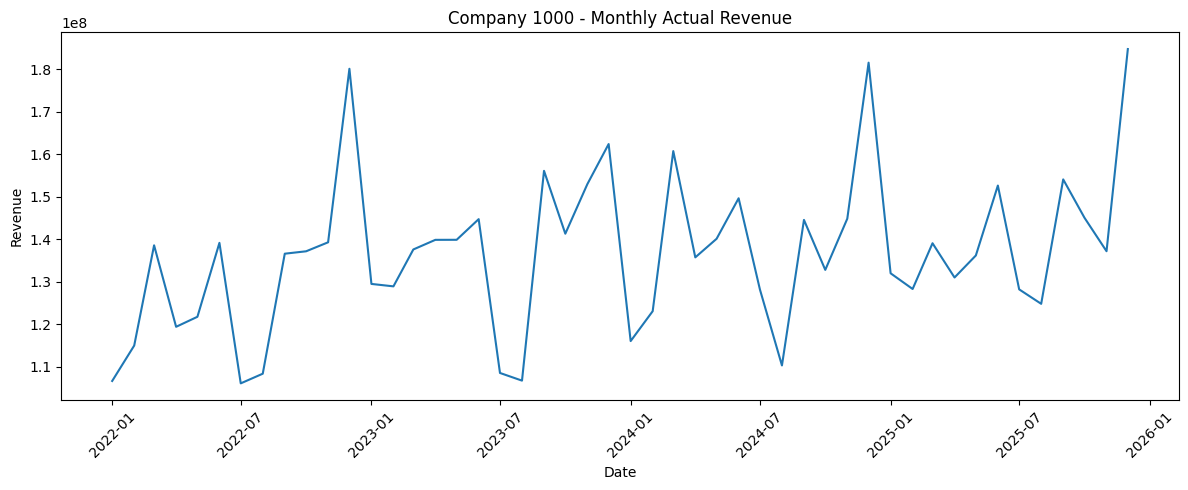

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    ml_revenue["date"],
    ml_revenue["Actual_Revenue"]
)

plt.title("Company 1000 - Monthly Actual Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [126]:
train = ml_revenue.iloc[:-12].copy()
test = ml_revenue.iloc[-12:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "to", test["date"].max())

Training observations: 36
Testing observations: 12

Training period:
2022-01-01 00:00:00 to 2024-12-01 00:00:00

Testing period:
2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [127]:
ml_revenue["lag_1"] = (
    ml_revenue["Actual_Revenue"].shift(1)
)

ml_revenue["lag_2"] = (
    ml_revenue["Actual_Revenue"].shift(2)
)

ml_revenue["lag_3"] = (
    ml_revenue["Actual_Revenue"].shift(3)
)

ml_revenue["lag_12"] = (
    ml_revenue["Actual_Revenue"].shift(12)
)

display(
    ml_revenue[
        [
            "date",
            "Actual_Revenue",
            "lag_1",
            "lag_2",
            "lag_3",
            "lag_12"
        ]
    ].head(20)
)

,date,Actual_Revenue,lag_1,lag_2,lag_3,lag_12
0,2022-01-01,1.066742e+08,NaN,NaN,NaN,NaN
1,2022-02-01,1.150038e+08,1.066742e+08,NaN,NaN,NaN
2,2022-03-01,1.385871e+08,1.150038e+08,1.066742e+08,NaN,NaN
3,2022-04-01,1.194189e+08,1.385871e+08,1.150038e+08,1.066742e+08,NaN
4,2022-05-01,1.217740e+08,1.194189e+08,1.385871e+08,1.150038e+08,NaN
5,2022-06-01,1.391669e+08,1.217740e+08,1.194189e+08,1.385871e+08,NaN
6,2022-07-01,1.061151e+08,1.391669e+08,1.217740e+08,1.194189e+08,NaN
7,2022-08-01,1.083876e+08,1.061151e+08,1.391669e+08,1.217740e+08,NaN
8,2022-09-01,1.366149e+08,1.083876e+08,1.061151e+08,1.391669e+08,NaN
9,2022-10-01,1.371788e+08,1.366149e+08,1.083876e+08,1.061151e+08,NaN


In [128]:
ml_revenue_model = ml_revenue.dropna().copy()

print(
    "Rows available for ML:",
    len(ml_revenue_model)
)

display(
    ml_revenue_model.head(10)
)

Rows available for ML: 36


,company_code,fiscal_year,fiscal_month,currency,Actual_Revenue,date,lag_1,lag_2,lag_3,lag_12
12,1000,2023,1,EUR,1.295041e+08,2023-01-01,1.801110e+08,1.392940e+08,1.371788e+08,1.066742e+08
13,1000,2023,2,EUR,1.289316e+08,2023-02-01,1.295041e+08,1.801110e+08,1.392940e+08,1.150038e+08
14,1000,2023,3,EUR,1.376094e+08,2023-03-01,1.289316e+08,1.295041e+08,1.801110e+08,1.385871e+08
15,1000,2023,4,EUR,1.398721e+08,2023-04-01,1.376094e+08,1.289316e+08,1.295041e+08,1.194189e+08
16,1000,2023,5,EUR,1.398843e+08,2023-05-01,1.398721e+08,1.376094e+08,1.289316e+08,1.217740e+08
17,1000,2023,6,EUR,1.447419e+08,2023-06-01,1.398843e+08,1.398721e+08,1.376094e+08,1.391669e+08
18,1000,2023,7,EUR,1.085609e+08,2023-07-01,1.447419e+08,1.398843e+08,1.398721e+08,1.061151e+08
19,1000,2023,8,EUR,1.067585e+08,2023-08-01,1.085609e+08,1.447419e+08,1.398843e+08,1.083876e+08
20,1000,2023,9,EUR,1.561054e+08,2023-09-01,1.067585e+08,1.085609e+08,1.447419e+08,1.366149e+08
21,1000,2023,10,EUR,1.413172e+08,2023-10-01,1.561054e+08,1.067585e+08,1.085609e+08,1.371788e+08


In [129]:
ml_train = ml_revenue_model.iloc[:-12].copy()
ml_test = ml_revenue_model.iloc[-12:].copy()

print("ML training observations:", len(ml_train))
print("ML testing observations:", len(ml_test))

print("\nTraining period:")
print(ml_train["date"].min(), "to", ml_train["date"].max())

print("\nTesting period:")
print(ml_test["date"].min(), "to", ml_test["date"].max())

ML training observations: 24
ML testing observations: 12

Training period:
2023-01-01 00:00:00 to 2024-12-01 00:00:00

Testing period:
2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [130]:
features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_12"
]

X_train = ml_train[features]
y_train = ml_train["Actual_Revenue"]

X_test = ml_test[features]
y_test = ml_test["Actual_Revenue"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (24, 4)
y_train shape: (24,)
X_test shape: (12, 4)
y_test shape: (12,)


In [131]:
from sklearn.ensemble import RandomForestRegressor

In [132]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=5
)

In [133]:
rf_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [134]:
y_pred = rf_model.predict(X_test)

print("Predictions generated:", len(y_pred))

Predictions generated: 12


In [135]:
forecast_results = ml_test[
    [
        "date",
        "Actual_Revenue"
    ]
].copy()

forecast_results["Predicted_Revenue"] = y_pred

display(forecast_results)

,date,Actual_Revenue,Predicted_Revenue
36,2025-01-01,1.320045e+08,1.281904e+08
37,2025-02-01,1.283116e+08,1.257041e+08
38,2025-03-01,1.390741e+08,1.623752e+08
39,2025-04-01,1.310151e+08,1.438726e+08
40,2025-05-01,1.361934e+08,1.419663e+08
41,2025-06-01,1.526426e+08,1.425444e+08
42,2025-07-01,1.282206e+08,1.363705e+08
43,2025-08-01,1.248236e+08,1.256837e+08
44,2025-09-01,1.540895e+08,1.474668e+08
45,2025-10-01,1.450556e+08,1.373768e+08


In [136]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

mape = (
    np.mean(
        np.abs(
            (y_test - y_pred) / y_test
        )
    )
    * 100
)

print("ML Revenue Forecast Performance")
print("--------------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

ML Revenue Forecast Performance
--------------------------------
MAE : 9165941.71
RMSE: 11530780.23
MAPE: 6.27 %


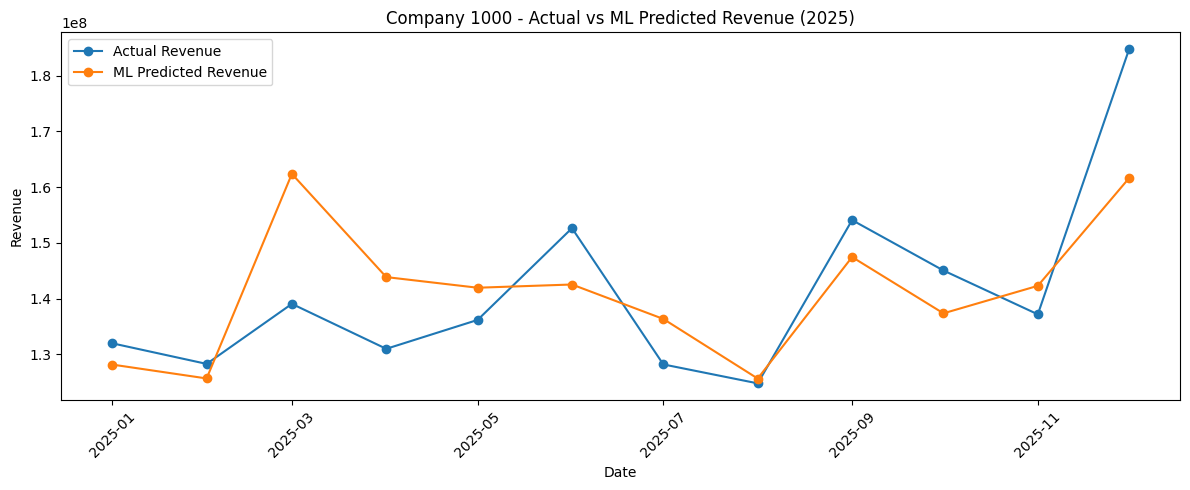

In [137]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_results["date"],
    forecast_results["Actual_Revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    forecast_results["date"],
    forecast_results["Predicted_Revenue"],
    marker="o",
    label="ML Predicted Revenue"
)

plt.title("Company 1000 - Actual vs ML Predicted Revenue (2025)")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [138]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
3,lag_12,0.677542
2,lag_3,0.174975
1,lag_2,0.085079
0,lag_1,0.062403


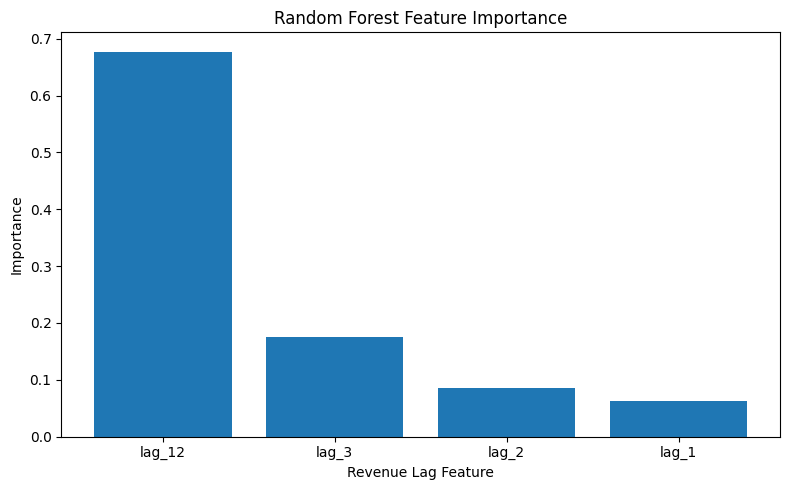

In [139]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Revenue Lag Feature")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

In [140]:
rolling_forecast_2025 = actual_budget_forecast[
    (actual_budget_forecast["company_code"] == 1000) &
    (actual_budget_forecast["fiscal_year"] == 2025)
][
    [
        "fiscal_year",
        "fiscal_month",
        "Forecast_Revenue"
    ]
].copy()

display(rolling_forecast_2025)

,fiscal_year,fiscal_month,Forecast_Revenue
36,2025,1,1.225036e+08
37,2025,2,1.254535e+08
38,2025,3,1.624823e+08
39,2025,4,1.393938e+08
40,2025,5,1.490777e+08
41,2025,6,1.599858e+08
42,2025,7,1.307892e+08
43,2025,8,1.214305e+08
44,2025,9,1.513447e+08
45,2025,10,1.446664e+08


In [141]:
forecast_results["fiscal_year"] = forecast_results["date"].dt.year
forecast_results["fiscal_month"] = forecast_results["date"].dt.month

display(forecast_results.head())

,date,Actual_Revenue,Predicted_Revenue,fiscal_year,fiscal_month
36,2025-01-01,1.320045e+08,1.281904e+08,2025,1
37,2025-02-01,1.283116e+08,1.257041e+08,2025,2
38,2025-03-01,1.390741e+08,1.623752e+08,2025,3
39,2025-04-01,1.310151e+08,1.438726e+08,2025,4
40,2025-05-01,1.361934e+08,1.419663e+08,2025,5


In [142]:
forecast_comparison = forecast_results.merge(
    rolling_forecast_2025,
    on=["fiscal_year", "fiscal_month"],
    how="inner"
)

forecast_comparison = forecast_comparison[
    [
        "date",
        "Actual_Revenue",
        "Forecast_Revenue",
        "Predicted_Revenue"
    ]
]

display(forecast_comparison)

,date,Actual_Revenue,Forecast_Revenue,Predicted_Revenue
0,2025-01-01,1.320045e+08,1.225036e+08,1.281904e+08
1,2025-02-01,1.283116e+08,1.254535e+08,1.257041e+08
2,2025-03-01,1.390741e+08,1.624823e+08,1.623752e+08
3,2025-04-01,1.310151e+08,1.393938e+08,1.438726e+08
4,2025-05-01,1.361934e+08,1.490777e+08,1.419663e+08
5,2025-06-01,1.526426e+08,1.599858e+08,1.425444e+08
6,2025-07-01,1.282206e+08,1.307892e+08,1.363705e+08
7,2025-08-01,1.248236e+08,1.214305e+08,1.256837e+08
8,2025-09-01,1.540895e+08,1.513447e+08,1.474668e+08
9,2025-10-01,1.450556e+08,1.446664e+08,1.373768e+08


In [143]:
rolling_mape = (
    np.mean(
        np.abs(
            (
                forecast_comparison["Actual_Revenue"]
                - forecast_comparison["Forecast_Revenue"]
            )
            / forecast_comparison["Actual_Revenue"]
        )
    )
    * 100
)

print(
    "Rolling Forecast MAPE:",
    round(rolling_mape, 2),
    "%"
)

Rolling Forecast MAPE: 5.69 %


In [144]:
ml_mape = (
    np.mean(
        np.abs(
            (
                forecast_comparison["Actual_Revenue"]
                - forecast_comparison["Predicted_Revenue"]
            )
            / forecast_comparison["Actual_Revenue"]
        )
    )
    * 100
)

print(
    "Random Forest MAPE:",
    round(ml_mape, 2),
    "%"
)

Random Forest MAPE: 6.27 %


In [145]:
forecast_method_comparison = pd.DataFrame({
    "Forecast_Method": [
        "Rolling Forecast",
        "Random Forest ML"
    ],
    "MAPE_%": [
        rolling_mape,
        ml_mape
    ]
})

forecast_method_comparison["MAPE_%"] = (
    forecast_method_comparison["MAPE_%"].round(2)
)

display(forecast_method_comparison)

,Forecast_Method,MAPE_%
0,Rolling Forecast,5.69
1,Random Forest ML,6.27


In [146]:
print(
    actuals_analysis["local_currency_amount"].describe()
)

count    1.599340e+05
mean     3.266729e+05
std      1.153534e+06
min      1.040000e+00
25%      1.015526e+04
50%      3.952067e+04
75%      1.439382e+05
max      3.855587e+07
Name: local_currency_amount, dtype: float64


In [147]:
amount_percentiles = (
    actuals_analysis["local_currency_amount"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999])
)

display(amount_percentiles)

0.500    3.952067e+04
0.750    1.439382e+05
0.900    6.229373e+05
0.950    1.590367e+06
0.990    5.506847e+06
0.995    7.656362e+06
0.999    1.405016e+07
Name: local_currency_amount, dtype: float64

In [148]:
anomaly_data = actuals_analysis[
    ["company_code", "fiscal_year", "fiscal_month",
     "financial_category", "gl_account",
     "local_currency_amount", "currency"]
].copy()

print("Transactions available for anomaly detection:", len(anomaly_data))

display(anomaly_data.head())

Transactions available for anomaly detection: 159934


,company_code,fiscal_year,fiscal_month,financial_category,gl_account,local_currency_amount,currency
0,1000,2022,1,REVENUE,400000,1804899.87,EUR
1,1000,2022,1,BALANCE_SHEET,140000,1804899.87,EUR
2,1000,2022,1,REVENUE,400000,755188.00,EUR
3,1000,2022,1,BALANCE_SHEET,140000,755188.00,EUR
4,1000,2022,1,REVENUE,400000,1772710.39,EUR


In [149]:
X_anomaly = anomaly_data[
    ["local_currency_amount"]
]

print("Anomaly model input shape:", X_anomaly.shape)

Anomaly model input shape: (159934, 1)


In [150]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42
)

isolation_forest.fit(X_anomaly)

print("Isolation Forest trained successfully.")

Isolation Forest trained successfully.


In [151]:
anomaly_data["anomaly_label"] = isolation_forest.predict(
    X_anomaly
)

display(
    anomaly_data[
        ["local_currency_amount", "anomaly_label"]
    ].head(20)
)

,local_currency_amount,anomaly_label
0,1804899.87,1
1,1804899.87,1
2,755188.00,1
3,755188.00,1
4,1772710.39,1
5,1772710.39,1
6,1155058.98,1
7,1155058.98,1
8,7719954.87,-1
9,7719954.87,-1


In [152]:
anomaly_counts = (
    anomaly_data["anomaly_label"]
    .value_counts()
)

print("Normal transactions:", anomaly_counts.get(1, 0))
print("Potential anomalies:", anomaly_counts.get(-1, 0))

Normal transactions: 158336
Potential anomalies: 1598


In [153]:
total_transactions = len(anomaly_data)

potential_anomalies = (
    anomaly_data["anomaly_label"] == -1
).sum()

anomaly_percentage = (
    potential_anomalies / total_transactions
) * 100

print(
    "Potential anomaly rate:",
    round(anomaly_percentage, 2),
    "%"
)

Potential anomaly rate: 1.0 %


In [154]:
potential_anomalies = anomaly_data[
    anomaly_data["anomaly_label"] == -1
].copy()

potential_anomalies = potential_anomalies.sort_values(
    "local_currency_amount",
    ascending=False
)

display(
    potential_anomalies.head(20)
)

,company_code,fiscal_year,fiscal_month,financial_category,gl_account,local_currency_amount,currency,anomaly_label
53102,1000,2025,5,REVENUE,400000,38555866.89,EUR,-1
53103,1000,2025,5,BALANCE_SHEET,140000,38555866.89,EUR,-1
159003,3000,2025,12,BALANCE_SHEET,140000,34322214.25,INR,-1
159002,3000,2025,12,REVENUE,400000,34322214.25,INR,-1
20714,1000,2023,4,REVENUE,400000,33371166.40,EUR,-1
20715,1000,2023,4,BALANCE_SHEET,140000,33371166.40,EUR,-1
27308,1000,2023,9,REVENUE,400000,32836422.76,EUR,-1
27309,1000,2023,9,BALANCE_SHEET,140000,32836422.76,EUR,-1
22011,1000,2023,5,BALANCE_SHEET,140000,29324491.57,EUR,-1
22010,1000,2023,5,REVENUE,400000,29324491.57,EUR,-1


In [155]:
print("Total transactions:", len(anomaly_data))

print(
    "Potential anomalies:",
    (anomaly_data["anomaly_label"] == -1).sum()
)

print(
    "Anomaly percentage:",
    round(
        (anomaly_data["anomaly_label"] == -1).mean() * 100,
        2
    ),
    "%"
)

Total transactions: 159934
Potential anomalies: 1598
Anomaly percentage: 1.0 %


In [156]:
anomaly_amount_summary = (
    potential_anomalies
    .groupby("currency")["local_currency_amount"]
    .agg(
        anomaly_transaction_count="count",
        total_flagged_amount="sum",
        average_flagged_amount="mean",
        maximum_flagged_amount="max"
    )
    .reset_index()
)

display(anomaly_amount_summary)

,currency,anomaly_transaction_count,total_flagged_amount,average_flagged_amount,maximum_flagged_amount
0,EUR,830,7.900266e+09,9.518393e+06,38555866.89
1,INR,508,4.473691e+09,8.806479e+06,34322214.25
2,USD,260,2.073592e+09,7.975353e+06,18851689.24


In [157]:
anomaly_category_summary = (
    potential_anomalies
    .groupby(
        ["financial_category", "currency"]
    )["local_currency_amount"]
    .agg(
        transaction_count="count",
        total_amount="sum",
        average_amount="mean"
    )
    .reset_index()
    .sort_values(
        "total_amount",
        ascending=False
    )
)

display(anomaly_category_summary)

,financial_category,currency,transaction_count,total_amount,average_amount
0,BALANCE_SHEET,EUR,415,3.950133e+09,9.518393e+06
7,REVENUE,EUR,324,3.188503e+09,9.841058e+06
1,BALANCE_SHEET,INR,254,2.236846e+09,8.806479e+06
8,REVENUE,INR,142,1.283887e+09,9.041457e+06
2,BALANCE_SHEET,USD,130,1.036796e+09,7.975353e+06
4,COGS,INR,109,9.344278e+08,8.572732e+06
9,REVENUE,USD,111,9.042834e+08,8.146697e+06
3,COGS,EUR,91,7.616303e+08,8.369563e+06
5,COGS,USD,19,1.325125e+08,6.974341e+06
6,PERSONNEL,INR,3,1.853085e+07,6.176950e+06


In [158]:
anomaly_model_data = anomaly_data.copy()

anomaly_model_data["category_code"] = (
    anomaly_model_data["financial_category"]
    .astype("category")
    .cat.codes
)

anomaly_model_data["debit_credit_code"] = (
    actuals_analysis.loc[
        anomaly_model_data.index,
        "debit_credit"
    ]
    .astype("category")
    .cat.codes
)

print(
    anomaly_model_data[
        [
            "local_currency_amount",
            "category_code",
            "debit_credit_code"
        ]
    ].head(10)
)

   local_currency_amount  category_code  debit_credit_code
0             1804899.87              5                  0
1             1804899.87              0                  1
2              755188.00              5                  0
3              755188.00              0                  1
4             1772710.39              5                  0
5             1772710.39              0                  1
6             1155058.98              5                  0
7             1155058.98              0                  1
8             7719954.87              5                  0
9             7719954.87              0                  1


In [159]:
X_anomaly_context = anomaly_model_data[
    [
        "local_currency_amount",
        "category_code",
        "debit_credit_code"
    ]
]

print(
    "Context-aware anomaly input:",
    X_anomaly_context.shape
)

Context-aware anomaly input: (159934, 3)


In [160]:
context_isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42
)

context_isolation_forest.fit(X_anomaly_context)

print("Context-aware Isolation Forest trained successfully.")

Context-aware Isolation Forest trained successfully.


In [161]:
anomaly_model_data["context_anomaly_label"] = (
    context_isolation_forest.predict(
        X_anomaly_context
    )
)

display(
    anomaly_model_data[
        [
            "local_currency_amount",
            "category_code",
            "debit_credit_code",
            "context_anomaly_label"
        ]
    ].head(20)
)

,local_currency_amount,category_code,debit_credit_code,context_anomaly_label
0,1804899.87,5,0,1
1,1804899.87,0,1,1
2,755188.00,5,0,1
3,755188.00,0,1,1
4,1772710.39,5,0,1
5,1772710.39,0,1,1
6,1155058.98,5,0,1
7,1155058.98,0,1,1
8,7719954.87,5,0,-1
9,7719954.87,0,1,-1


In [162]:
context_anomaly_count = (
    anomaly_model_data["context_anomaly_label"] == -1
).sum()

context_anomaly_rate = (
    context_anomaly_count
    / len(anomaly_model_data)
) * 100

print("Potential anomalies:", context_anomaly_count)
print(
    "Potential anomaly rate:",
    round(context_anomaly_rate, 2),
    "%"
)

Potential anomalies: 1578
Potential anomaly rate: 0.99 %


In [163]:
original_anomaly_count = (
    anomaly_data["anomaly_label"] == -1
).sum()

comparison = pd.DataFrame({
    "Model": [
        "Amount Only",
        "Amount + Category + Debit/Credit"
    ],
    "Potential_Anomalies": [
        original_anomaly_count,
        context_anomaly_count
    ]
})

comparison["Anomaly_Rate_%"] = (
    comparison["Potential_Anomalies"]
    / len(anomaly_data)
    * 100
)

comparison["Anomaly_Rate_%"] = (
    comparison["Anomaly_Rate_%"].round(2)
)

display(comparison)

,Model,Potential_Anomalies,Anomaly_Rate_%
0,Amount Only,1598,1.00
1,Amount + Category + Debit/Credit,1578,0.99


In [164]:
comparison_details = anomaly_model_data[
    anomaly_model_data["context_anomaly_label"]
    != anomaly_data["anomaly_label"]
].copy()

print(
    "Transactions with different anomaly classification:",
    len(comparison_details)
)

display(
    comparison_details[
        [
            "company_code",
            "fiscal_year",
            "fiscal_month",
            "financial_category",
            "local_currency_amount",
            "category_code",
            "debit_credit_code",
            "context_anomaly_label"
        ]
    ].head(20)
)

Transactions with different anomaly classification: 218


,company_code,fiscal_year,fiscal_month,financial_category,local_currency_amount,category_code,debit_credit_code,context_anomaly_label
1789,1000,2022,2,BALANCE_SHEET,5223880.03,0,0,-1
2689,1000,2022,3,BALANCE_SHEET,5453152.57,0,0,-1
2922,1000,2022,3,REVENUE,5192933.47,5,0,-1
3305,1000,2022,3,BALANCE_SHEET,5573852.46,0,1,1
3654,1000,2022,3,REVENUE,5233218.88,5,0,-1
4982,1000,2022,4,REVENUE,5364828.38,5,0,-1
6222,1000,2022,5,REVENUE,5429380.45,5,0,-1
6340,1000,2022,5,COGS,5658385.37,1,1,1
7186,1000,2022,6,REVENUE,5218869.96,5,0,-1
7524,1000,2022,6,REVENUE,5210716.31,5,0,-1


In [165]:
anomaly_investigation = anomaly_model_data[
    anomaly_model_data["context_anomaly_label"] == -1
].copy()

anomaly_investigation = anomaly_investigation[
    [
        "company_code",
        "fiscal_year",
        "fiscal_month",
        "financial_category",
        "gl_account",
        "local_currency_amount",
        "currency",
        "debit_credit_code",
        "context_anomaly_label"
    ]
].copy()

anomaly_investigation = anomaly_investigation.sort_values(
    "local_currency_amount",
    ascending=False
)

print(
    "Potential anomalies for investigation:",
    len(anomaly_investigation)
)

display(anomaly_investigation.head(20))

Potential anomalies for investigation: 1578


,company_code,fiscal_year,fiscal_month,financial_category,gl_account,local_currency_amount,currency,debit_credit_code,context_anomaly_label
53103,1000,2025,5,BALANCE_SHEET,140000,38555866.89,EUR,1,-1
53102,1000,2025,5,REVENUE,400000,38555866.89,EUR,0,-1
159002,3000,2025,12,REVENUE,400000,34322214.25,INR,0,-1
159003,3000,2025,12,BALANCE_SHEET,140000,34322214.25,INR,1,-1
20714,1000,2023,4,REVENUE,400000,33371166.40,EUR,0,-1
20715,1000,2023,4,BALANCE_SHEET,140000,33371166.40,EUR,1,-1
27308,1000,2023,9,REVENUE,400000,32836422.76,EUR,0,-1
27309,1000,2023,9,BALANCE_SHEET,140000,32836422.76,EUR,1,-1
22011,1000,2023,5,BALANCE_SHEET,140000,29324491.57,EUR,1,-1
22010,1000,2023,5,REVENUE,400000,29324491.57,EUR,0,-1


In [166]:
anomaly_category_summary = (
    anomaly_investigation
    .groupby(
        ["financial_category", "currency"]
    )
    .agg(
        anomaly_count=("local_currency_amount", "count"),
        total_anomaly_amount=("local_currency_amount", "sum"),
        average_anomaly_amount=("local_currency_amount", "mean")
    )
    .reset_index()
    .sort_values(
        "total_anomaly_amount",
        ascending=False
    )
)

display(anomaly_category_summary)

,financial_category,currency,anomaly_count,total_anomaly_amount,average_anomaly_amount
0,BALANCE_SHEET,EUR,397,3.840880e+09,9.674761e+06
7,REVENUE,EUR,352,3.337524e+09,9.481602e+06
1,BALANCE_SHEET,INR,243,2.168726e+09,8.924797e+06
8,REVENUE,INR,157,1.363593e+09,8.685307e+06
9,REVENUE,USD,124,9.735356e+08,7.851094e+06
2,BALANCE_SHEET,USD,113,9.368707e+08,8.290891e+06
4,COGS,INR,93,8.423262e+08,9.057271e+06
3,COGS,EUR,79,6.896092e+08,8.729230e+06
5,COGS,USD,16,1.137257e+08,7.107857e+06
6,PERSONNEL,INR,4,2.390638e+07,5.976596e+06


In [167]:
category_transaction_counts = (
    actuals_analysis
    .groupby(
        ["financial_category", "currency"]
    )
    .size()
    .reset_index(name="total_transactions")
)

category_anomaly_rate = anomaly_category_summary.merge(
    category_transaction_counts,
    on=["financial_category", "currency"],
    how="left"
)

category_anomaly_rate["anomaly_rate_%"] = (
    category_anomaly_rate["anomaly_count"]
    / category_anomaly_rate["total_transactions"]
    * 100
)

category_anomaly_rate["anomaly_rate_%"] = (
    category_anomaly_rate["anomaly_rate_%"].round(2)
)

display(
    category_anomaly_rate.sort_values(
        "anomaly_rate_%",
        ascending=False
    )
)

,financial_category,currency,anomaly_count,total_anomaly_amount,average_anomaly_amount,total_transactions,anomaly_rate_%
1,REVENUE,EUR,352,3.337524e+09,9.481602e+06,2702,13.03
3,REVENUE,INR,157,1.363593e+09,8.685307e+06,2006,7.83
4,REVENUE,USD,124,9.735356e+08,7.851094e+06,2029,6.11
6,COGS,INR,93,8.423262e+08,9.057271e+06,2023,4.60
7,COGS,EUR,79,6.896092e+08,8.729230e+06,2745,2.88
0,BALANCE_SHEET,EUR,397,3.840880e+09,9.674761e+06,31197,1.27
2,BALANCE_SHEET,INR,243,2.168726e+09,8.924797e+06,22173,1.10
8,COGS,USD,16,1.137257e+08,7.107857e+06,1984,0.81
5,BALANCE_SHEET,USD,113,9.368707e+08,8.290891e+06,26597,0.42
9,PERSONNEL,INR,4,2.390638e+07,5.976596e+06,7328,0.05


In [168]:
overall_anomaly_rate = (
    (anomaly_model_data["context_anomaly_label"] == -1).sum()
    / len(anomaly_model_data)
) * 100

print(
    "Overall Potential Anomaly Rate:",
    round(overall_anomaly_rate, 2),
    "%"
)

Overall Potential Anomaly Rate: 0.99 %


In [169]:
final_kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Accounting Transactions",
        "Total Documents",
        "Document Reconciliation Rate",
        "Revenue Forecast MAPE",
        "ML Revenue Forecast MAPE",
        "Potential Financial Anomalies",
        "Overall Anomaly Rate"
    ],
    
    "Value": [
        len(actuals_analysis),
        len(document_balance),
        (
            (document_balance["balance_difference"].abs() < 0.01).mean()
            * 100
        ),
        revenue_mape,
        ml_mape,
        context_anomaly_count,
        overall_anomaly_rate
    ]
})

final_kpi_summary["Value"] = final_kpi_summary["Value"].round(2)

display(final_kpi_summary)

,KPI,Value
0,Total Accounting Transactions,159934.00
1,Total Documents,79967.00
2,Document Reconciliation Rate,100.00
3,Revenue Forecast MAPE,6.86
4,ML Revenue Forecast MAPE,6.27
5,Potential Financial Anomalies,1578.00
6,Overall Anomaly Rate,0.99


In [170]:
business_insights = pd.DataFrame({
    "Metric": [
        "Best Revenue Forecast MAPE",
        "ML Forecast MAPE",
        "ML vs Revenue Forecast Improvement",
        "ML vs Rolling Forecast Difference",
        "Highest Revenue Anomaly Rate",
        "Overall Potential Anomaly Rate"
    ],
    
    "Value": [
        rolling_mape,
        ml_mape,
        revenue_mape - ml_mape,
        ml_mape - rolling_mape,
        category_anomaly_rate["anomaly_rate_%"].max(),
        overall_anomaly_rate
    ]
})

business_insights["Value"] = (
    business_insights["Value"].round(2)
)

display(business_insights)

,Metric,Value
0,Best Revenue Forecast MAPE,5.69
1,ML Forecast MAPE,6.27
2,ML vs Revenue Forecast Improvement,0.59
3,ML vs Rolling Forecast Difference,0.58
4,Highest Revenue Anomaly Rate,13.03
5,Overall Potential Anomaly Rate,0.99


In [171]:
actual_budget_forecast.to_csv(
    "/kaggle/working/actual_budget_forecast.csv",
    index=False
)

print("Main FP&A dataset exported successfully.")

Main FP&A dataset exported successfully.


In [172]:
import os

print(
    "File exists:",
    os.path.exists(
        "/kaggle/working/actual_budget_forecast.csv"
    )
)

File exists: True


In [173]:
anomaly_investigation.to_csv(
    "/kaggle/working/anomaly_investigation.csv",
    index=False
)

print("Anomaly dataset exported successfully.")

Anomaly dataset exported successfully.


In [174]:
import os

print(
    "File exists:",
    os.path.exists(
        "/kaggle/working/anomaly_investigation.csv"
    )
)

File exists: True


In [175]:
forecast_results.to_csv(
    "/kaggle/working/forecast_results.csv",
    index=False
)

print("ML forecast dataset exported successfully.")

ML forecast dataset exported successfully.


In [176]:
import os

print(
    "File exists:",
    os.path.exists(
        "/kaggle/working/forecast_results.csv"
    )
)

File exists: True


In [177]:
final_kpi_summary.to_csv(
    "/kaggle/working/final_kpi_summary.csv",
    index=False
)

print("KPI summary exported successfully.")

KPI summary exported successfully.


In [178]:
import os

print(
    "File exists:",
    os.path.exists(
        "/kaggle/working/final_kpi_summary.csv"
    )
)

File exists: True
